# 04 - SVM method

**Aim:** implement the practical SVM protocol for signal-peptide detection, with feature extraction and parameter selection inside nested cross-validation.

We used the practical instructions in `04 - Methods - SVM.pdf` to plan this section. We reused the representative proteins and folds from 02b, built composition, hydropathy, charge and propensity features, and selected the SVM settings using training data only. The analysis in 02c provides biological context, and 03 provides our loading and reporting conventions.

**Materials**
- `04 - Methods - SVM.pdf` (slides 22–26 and 30–41; practical instructions on slide 41).
- `04_feature_extraction_hydrophobicity.ipynb` (setup, A.1–A.5 and B.4).
- `04_SVM-sklearn_revised.ipynb` (sections 1–3 and 7).
- `03_von_heijne_method.ipynb` (loading in 1.1; metrics and mean ± SE in 5.4–5.6).

- External feature rationale: [feature notes](../docs/04_feature_candidates.md).

The [supplementary feature exploration](04_feature_exploration.ipynb) compares training profiles and distributions for the 11 non-composition features; its figures and observations are available. Composition context remains in 02c.

**Status:** fixed-grid evaluation and reporting completed and checked; ready for review.

## Workflow and shared definitions

We loaded the prepared proteins, defined the features and fitted the selection/classification procedure inside nested cross-validation. The following objects connect the scientific steps. All fitted quantities belong to their current training subset.

| Object | Interface |
| --- | --- |
| `data` | Training proteins with `accession`, `sequence`, `label`, `split`, `cv_fold` and original metadata. |
| `get_n(train_data)` | Integer N-terminal length derived only from positive SP lengths in the supplied training subset. |
| `extract_features(proteins, n)` | Numeric DataFrame indexed by accession, with the same ordered feature columns for every subset. |
| RF ranking | Column indices ordered by importance, plus names and importances from the current training fit. |
| Search candidates | Valid tuples `(k, C, gamma)`, with gamma calculated for that candidate's k. |
| `inner_scores` | `test_fold`, `validation_fold`, `n`, `k`, `C`, `gamma`, `mcc`. |
| `cv_per_round` | `test_fold`, `n`, `selected_k`, `C`, `gamma`, `mcc`, `f1`, `precision`, `recall`, `accuracy`. |
| `cv_predictions` | `accession`, `test_fold`, `label`, `prediction`. |
| `selected_features` | `test_fold`, `feature`, `rank`, `importance`, after the outer-training refit. |



## 0. Data loading

We kept paths relative to `notebooks/` and selected the Conda `LB2` environment and the same kernel as 03.

### 0.1 Imports and paths

We prepared the libraries for data handling, plotting, RF selection, scaling, SVM classification and evaluation, following the imports in the SVM example. We kept relative paths from `notebooks/`, as in 03. We created the folders for this section's tables and figures.

The Kyte–Doolittle scale is imported in 1.2 using Biopython, listed in `requirements.txt`.

We used text progress bars from `tqdm`, which do not require Jupyter widgets.

**Similar code:** imports in `04_SVM-sklearn_revised.ipynb`, section 0; relative paths and plot settings in 03 section 0.

In [1]:
# Imports follow section 0 in 04_SVM-sklearn_revised.ipynb.
# Path handling follows section 0 in 03_von_heijne_method.ipynb.
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Text progress bars work without Jupyter widgets.
from tqdm import tqdm

from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import (
    matthews_corrcoef,
    precision_score,
    recall_score,
    f1_score,
    accuracy_score,
)

# These paths and plot settings follow section 0 in 03_von_heijne_method.ipynb.
input_dir = Path("../data/prepared")
table_dir = Path("../results/tables/04")
figure_dir = Path("../results/figures/04")

table_dir.mkdir(parents=True, exist_ok=True)
figure_dir.mkdir(parents=True, exist_ok=True)

sns.set_theme()


### 0.2 Load the prepared proteins

We reused the FASTA reader and accession mapping from 03. The TSV files provide the metadata, and the matching FASTA files provide the sequences. We attached each sequence by accession and assigned label 1 to SP and 0 to NO_SP. The loaded tables contain 8,146 training proteins and 2,038 benchmarking proteins.

We kept the split and fold assignments from 02b. Cross-validation will use `data`, containing the training proteins; `benchmarking_data` will remain separate. Fold identifiers stay 1–5, with missing fold values allowed for benchmarking.

**Similar code:** 03 section 1.1 supplies this loader. The SVM example section 1 uses a random split of another dataset; we retained our prepared partitions instead.

In [2]:
# This reader is reused from section 1.1 in 03_von_heijne_method.ipynb.
def read_fasta(fasta_path):
    sequences = {}
    with open(fasta_path, encoding="utf-8") as fasta_in:
        for line in fasta_in:
            line = line.strip()
            if line.startswith(">"):
                accession = line[1:].split()[0]
                sequences[accession] = ""
            elif line:
                sequences[accession] += line
    return sequences


# TSV/FASTA loading and accession mapping also follow section 1.1 in that notebook.
positive_data = pd.read_csv(
    input_dir / "positive_dataset.tsv", sep="\t", dtype={"cv_fold": "Int64"}
)
negative_data = pd.read_csv(
    input_dir / "negative_dataset.tsv", sep="\t", dtype={"cv_fold": "Int64"}
)
positive_sequences = read_fasta(input_dir / "positive_dataset.fasta")
negative_sequences = read_fasta(input_dir / "negative_dataset.fasta")

positive_data["sequence"] = positive_data["accession"].map(positive_sequences)
negative_data["sequence"] = negative_data["accession"].map(negative_sequences)
positive_data["label"] = 1
negative_data["label"] = 0

# Keep the saved partitions, as in 03 section 1.1; no random split from the SVM example.
prepared_data = pd.concat([positive_data, negative_data], ignore_index=True)
data = prepared_data[prepared_data["split"] == "training"].copy()
benchmarking_data = prepared_data[prepared_data["split"] == "benchmarking"].copy()

print("Training proteins:", len(data))
print("Benchmarking proteins:", len(benchmarking_data))


Training proteins: 8146
Benchmarking proteins: 2038


## 1. Common feature definitions

We separated fixed choices from quantities learned in each training subset. The composition length n will be learned from positive training proteins; it is not a fixed 90-residue window (slides 30 and 36–40).

### 1.1 Estimate n from the current training subset

We defined `get_n(train_data)` to estimate the composition length from the positive proteins in the supplied training subset (slides 30 and 40). Their `cleavage_pos` gives the last SP residue and therefore the annotated SP length.

We chose to round a half-integer median upward so n can be used for sequence slicing. This is our convention; the slides do not specify a rounding rule.

The function will be called separately for each three-fold inner-training set and again for the four-fold outer-training refit. The resulting n will also be used for that split's validation or test proteins. `cleavage_pos` contributes only to this training estimate, not to the predictor matrix.

**Similar code:** neither practical notebook includes this helper. Slide 40 specifies the calculation, and 02c establishes the meaning of `cleavage_pos`.

In [3]:
# This helper implements the training-only median in slides 30 and 40 of
# 04 - Methods - SVM.pdf; neither practical example contains an equivalent function.
def get_n(train_data):
    sp_lengths = train_data.loc[train_data["label"] == 1, "cleavage_pos"]
    median_length = sp_lengths.median()
    # Rounding upward is our project convention, not a rule from the examples.
    return int(np.ceil(median_length))


### 1.2 Fixed feature settings and residue policy

We used the Kyte–Doolittle scale supplied by Biopython, as in the hydrophobicity example. Positive values indicate hydrophobic residues and negative values indicate hydrophilic residues. We chose the first 40 residues and windows of 5, following the starting example in slides 32–34. We also chose the first 5 residues for a charge-balance feature (2.3). For the regional features in 2.6, we chose a hydropathy threshold of 0, a downstream region of 5 positions and explicit small-residue sets. These are simple project choices, not fitted parameters or published optimal settings. For the propensity profiles in 2.4–2.5, we chose the first 40 residues with windows of 5 for alpha-helix propensity and 19 for transmembrane tendency. These window sizes are project choices. All these settings stay fixed during the k/C/gamma search; composition uses its separately estimated n.

We chose complete windows with uniform weights and no padding. The extractor preserves unknown positions and averages the known values within each original window. A window with no known values is missing, and the profile summaries use the non-missing values. Composition and charge balance exclude non-canonical residues from their denominators. Shorter sequences use the available N-terminal region.

We kept the canonical amino-acid alphabet in the same order as the composition columns. We kept the published scale dictionaries here with the common settings. Feature extraction belongs to section 2.

**Similar code:** setup and A.1–A.3 in `04_feature_extraction_hydrophobicity.ipynb` supply the scale and complete-window example. A.5 explains known-residue averaging; we adapted it to complete windows. The added regional settings are project choices, not implementations from that notebook.


In [4]:
# Scale lookup follows setup and A.1 in 04_feature_extraction_hydrophobicity.ipynb.
from Bio.SeqUtils.ProtParamData import kd

hydropathy_scale = kd
# Shared alphabet for our composition extractor; not supplied by the hydropathy example.
aa_alphabet = list("ACDEFGHIKLMNPQRSTVWY")

# Region and window follow the starting example on slide 34 of 04 - Methods - SVM.pdf.
hydropathy_length = 40
hydropathy_window = 5

# Fixed region for our charge proxy in 2.3; an extension of SVM slide 32.
charge_length = 5

# Fixed project settings for the regional extensions in 2.6; not class defaults.
hydropathy_threshold = 0.0
postpeak_length = 5
postpeak_small_residues = "AGS"
cleavage_small_residues = "ACGST"

# Additional scale profiles follow SVM slides 31 and 34; window sizes are our choices.
propensity_length = 40
alpha_helix_window = 5
tm_tendency_window = 19

# Published values from ProtScale; scale lookup follows A.1 in
# 04_feature_extraction_hydrophobicity.ipynb, replacing its KD dictionary.
# Chou-Fasman: https://web.expasy.org/protscale/pscale/alpha-helixFasman.html
alpha_helix_scale = {
    "A": 1.42, "C": 0.70, "D": 1.01, "E": 1.51, "F": 1.13,
    "G": 0.57, "H": 1.00, "I": 1.08, "K": 1.16, "L": 1.21,
    "M": 1.45, "N": 0.67, "P": 0.57, "Q": 1.11, "R": 0.98,
    "S": 0.77, "T": 0.83, "V": 1.06, "W": 1.08, "Y": 0.69,
}
# Zhao-London: https://web.expasy.org/protscale/pscale/Transmembranetendency.html
tm_tendency_scale = {
    "A": 0.38, "C": -0.30, "D": -3.27, "E": -2.90, "F": 1.98,
    "G": -0.19, "H": -1.44, "I": 1.97, "K": -3.46, "L": 1.82,
    "M": 1.40, "N": -1.62, "P": -1.44, "Q": -1.84, "R": -2.57,
    "S": -0.53, "T": -0.32, "V": 1.46, "W": 1.53, "Y": 0.49,
}



## 2. Feature extraction

We started with the 20 amino-acid fractions and two hydropathy summaries from slides 30–34. We then added charge balance, peak position, hydrophobic extent, post-peak small-residue fraction and cleavage-motif support; the user-run example produced 27 columns with no missing values.

Following slides 31 and 34, we added mean and maximum profiles for alpha-helix propensity and transmembrane tendency, giving 31 features. We executed the complete extractor and obtained 31 columns with no missing values. Sections 4–6 report the nested cross-validation results. Sections 2.3–2.6 explain the extensions.

We ordered the groups as composition, hydropathy, charge and the two propensities proposed in the slides, followed by our additional sequence features. Specific formulas and scale choices are documented with their sources.


### 2.1 N-terminal amino-acid composition

We defined `amino_acid_composition(sequence, n)`, which counts the canonical residues in the available first n positions and returns their fractions in the alphabet order `ACDEFGHIKLMNPQRSTVWY`. The 20 values are named `aa_fraction_A` to `aa_fraction_Y` and sum to 1 (slide 30).

Following the residue policy in 1.2, non-canonical residues are excluded from both the counts and the denominator, so each fraction describes the observed canonical residues rather than the full segment. Two training proteins (Q27972 and P02809) carry an X in this region; the remaining 8,144 are fully canonical, and no benchmarking protein is affected. A segment containing no canonical residue returns missing values rather than zeros, so an empty denominator cannot be reported as a composition of zeros.

The function receives n from its caller and never estimates it. It does not read `cleavage_pos`, so a protein's own annotation cannot choose its region; only `get_n` uses that column, on training positives.

We checked the function against the worked example on slide 30. For the first 21 residues of `MRFLAATFLLLALSTAAQAEPQF` it reproduces the published vector: A 0.29, L 0.24, F 0.10, T 0.10, and 0.05 for E, M, P, Q, R and S. For display, we listed all 20 amino acids in one table, including zero fractions and using two decimal places. The extractor's column order stays unchanged.

**Similar code:** the practical notebooks do not include this composition function. We adapted the canonical counting in 02c section 5.2 from pooled class counts to individual proteins; slide 30 defines the required vector.

In [5]:
composition_feature_names = [f"aa_fraction_{amino_acid}" for amino_acid in aa_alphabet]


# This function adapts the counting in section 5.2 of 02c_data_analysis.ipynb
# to individual proteins, producing the vector defined on slide 30 of the SVM slides.
def amino_acid_composition(sequence, n):
    """Fractions of the canonical residues within the first n positions."""
    counts = dict.fromkeys(aa_alphabet, 0)
    observed = 0
    for residue in sequence[:n]:
        if residue in counts:
            counts[residue] += 1
            observed += 1
    if observed == 0:
        return {name: np.nan for name in composition_feature_names}
    return {
        f"aa_fraction_{amino_acid}": counts[amino_acid] / observed
        for amino_acid in aa_alphabet
    }


# This sequence and n=21 reproduce the worked example on slide 30 of 04 - Methods - SVM.pdf.
slide_example = amino_acid_composition("MRFLAATFLLLALSTAAQAEPQF", 21)
composition_table = pd.DataFrame(
    [[slide_example[f"aa_fraction_{amino_acid}"] for amino_acid in aa_alphabet]],
    columns=aa_alphabet,
    index=["Fraction"],
)

print("N-terminal amino acid composition for slide example:")

with pd.option_context("display.max_columns", 20):
    display(composition_table.round(2))

print("Fractions sum to:", round(sum(slide_example.values()), 12))


N-terminal amino acid composition for slide example:


,A,C,D,E,F,G,H,I,K,L,M,N,P,Q,R,S,T,V,W,Y
Fraction,0.29,0.0,0.0,0.05,0.1,0.0,0.0,0.0,0.0,0.24,0.05,0.0,0.05,0.05,0.05,0.05,0.1,0.0,0.0,0.0


Fractions sum to: 1.0


### 2.2 Hydropathy profile and summaries

We wrote the profile explicitly instead of calling `protein_scale`, because Biopython handles residues outside the scale by warning and skipping their symmetric partners within a window, whereas our policy in 1.2 averages the known values without shifting positions. `hydropathy_profile(sequence)` takes the first 40 residues, maps each to its Kyte–Doolittle value, and averages the known values inside every complete 5-position window with uniform weights and no padding. A canonical segment of length L therefore gives L − w + 1 window values; the shortest training protein is exactly 40 residues long, so every training profile contains 36 values. A window whose five positions are all unknown is recorded as missing.

`hydropathy_features(sequence)` summarizes the non-missing window values as `hydropathy_max_w5` and `hydropathy_profile_mean_w5` (slide 34). The mean is taken over the window profile rather than over the 40 residue values directly, so the first and last four residues contribute to fewer windows than the interior ones.

We compared the first 300 fully canonical N-termini with `ProteinAnalysis.protein_scale(kd, 5)` and obtained a largest difference of 8.9e-16. The output also shows missing values for both features on 40 unknown residues. We reused the window calculation in `scale_profile(sequence, scale, window, length)` and kept `hydropathy_profile` as the KD wrapper. Replacing a residue with X would preserve the profile length and could affect only windows containing that position; this follows from keeping the original positions when forming windows.

The maximum and the mean describe the same profile from two directions. The maximum reports the strongest local hydrophobic peak, which may reflect an SP h-region or another hydrophobic segment, and the mean reports how hydrophobic the N-terminus is overall; a short strong peak and a broad mild one can share a mean but not a maximum.

**Similar code:** `window_profile` in hydrophobicity notebook A.2 is the closest loop, and A.3 compares it with `ProteinAnalysis.protein_scale`. A.5 explains the unknown-residue issue, which we handled with the complete windows chosen in 1.2 rather than its shrinking windows; B.4 shows the profile-to-feature aggregation. Slide 34 gives the max/mean pair.

In [6]:
hydropathy_feature_names = [
    f"hydropathy_max_w{hydropathy_window}",
    f"hydropathy_profile_mean_w{hydropathy_window}",
]


# This function combines A.1 (residue values) and A.2 (window_profile) in
# 04_feature_extraction_hydrophobicity.ipynb, with the unknown-residue policy from A.5.
def scale_profile(sequence, scale, window, length):
    """Complete-window means for a residue scale, retaining unknown positions."""
    # Similar to A.1: look up one scale value per residue, retaining unknown positions.
    values = [
        scale.get(residue, np.nan)
        for residue in sequence[:length]
    ]
    profile = []
    # Similar to window_profile in A.2: slide only complete windows along the sequence.
    for start in range(len(values) - window + 1):
        # Adapted from A.5: average known residues, without shrinking the end windows.
        window_values = [
            value
            for value in values[start : start + window]
            if not np.isnan(value)
        ]
        profile.append(float(np.mean(window_values)) if window_values else np.nan)
    return profile


# KD wrapper around the shared A.2-style loop; existing feature functions keep
# the same interface and fixed settings from SVM slide 34.
def hydropathy_profile(sequence):
    """Complete-window KD profile over the fixed N-terminal region."""
    return scale_profile(sequence, hydropathy_scale, hydropathy_window, hydropathy_length)


# This function follows profile aggregation in B.4 of
# 04_feature_extraction_hydrophobicity.ipynb and the max/mean pair on SVM slide 34.
def hydropathy_features(sequence):
    """Maximum and mean of the non-missing window values of the profile."""
    profile = [value for value in hydropathy_profile(sequence) if not np.isnan(value)]
    if not profile:
        return {name: np.nan for name in hydropathy_feature_names}
    return dict(zip(hydropathy_feature_names, [max(profile), float(np.mean(profile))]))


# This comparison follows A.3 in 04_feature_extraction_hydrophobicity.ipynb:
# compare our explicit loop with ProteinAnalysis.protein_scale on canonical sequences.
from Bio.SeqUtils.ProtParam import ProteinAnalysis

canonical_sequences = [
    sequence
    for sequence in data["sequence"]
    if set(sequence[:hydropathy_length]) <= set(aa_alphabet)
]
largest_difference = max(
    abs(ours - reference)
    for sequence in canonical_sequences[:300]
    for ours, reference in zip(
        hydropathy_profile(sequence),
        ProteinAnalysis(sequence[:hydropathy_length]).protein_scale(
            hydropathy_scale, hydropathy_window
        ),
    )
)

print(f"Canonical N-termini: {len(canonical_sequences)} of {len(data)} training proteins")
print(f"Largest difference from protein_scale (first 300): {largest_difference:.1e}")
print("Profile values per 40-residue segment:", len(hydropathy_profile("A" * 40)))
# Project check for the missing-value behavior motivated by A.5.
print("All-unknown segment:", hydropathy_features("X" * 40))

Canonical N-termini: 8144 of 8146 training proteins
Largest difference from protein_scale (first 300): 8.9e-16
Profile values per 40-residue segment: 36
All-unknown segment: {'hydropathy_max_w5': nan, 'hydropathy_profile_mean_w5': nan}


### 2.3 N-terminal charge

Charge is one of the feature categories proposed on slide 31. We chose `nterminal_charge(sequence)` to calculate `(K + R - D - E counts) / canonical residue count` over the first 5 positions. Other canonical residues, including H, score zero; unknown residues are excluded from the denominator. `charge_features(sequence)` returns this value in a named dictionary for the assembled extractor.

[Guo et al. (2018)](https://pubmed.ncbi.nlm.nih.gov/29229776/) found a role for positive n-region charge in the post-translational translocation of small secretory preproteins. Our formula and first-5 region are project choices, not a universal SP rule or a reproduction of that experiment. The result is a charge proxy, not physical net charge at a specified pH; its predictive value still needs evaluation.

**Similar code:** charge counting resembles the composition loop in 2.1. Neither class notebook supplies this exact formula; slide 31 proposes charge and slide 32 illustrates the positive n-region.


In [7]:
charge_feature_names = [f"nterminal_charge_first{charge_length}"]


# Project extension: residue counting like 2.1, motivated by SVM slide 32 and
# Guo et al. (2018); no equivalent charge function in the class notebooks.
def nterminal_charge(sequence):
    """Mean K/R (+1) and D/E (-1) proxy over canonical residues in the first 5 positions."""
    residues = [residue for residue in sequence[:charge_length] if residue in aa_alphabet]
    if not residues:
        return np.nan
    positive = sum(residue in "KR" for residue in residues)
    negative = sum(residue in "DE" for residue in residues)
    return (positive - negative) / len(residues)


# Project grouping, like the feature dictionary in B.4 of
# 04_feature_extraction_hydrophobicity.ipynb; charge is proposed on SVM slide 31.
def charge_features(sequence):
    """N-terminal charge proxy as a named feature dictionary."""
    return {charge_feature_names[0]: nterminal_charge(sequence)}


### 2.4 Alpha-helix propensity profile and summaries

We chose the [Chou–Fasman alpha-helix scale from ProtScale](https://web.expasy.org/protscale/pscale/alpha-helixFasman.html), based on amino-acid frequencies in known structures. Its values were included in the shared definitions in 1.2. Higher values indicate greater alpha-helix propensity.

`alpha_helix_profile(sequence)` uses the first 40 residues and complete windows of 5, with the same unknown-residue policy as hydropathy. `alpha_helix_features(sequence)` returns the mean and maximum of the non-missing window values. An empty or entirely missing profile gives NaN for both features. These summaries describe sequence propensity; they do not assign secondary structure to individual residues or implement the full Chou–Fasman prediction method.

We chose the region and window size before evaluation and kept them fixed. Their value for SP classification still needs CV evaluation.

**Similar code:** A.1–A.2 in `04_feature_extraction_hydrophobicity.ipynb` map scale values and build a window profile; B.4 summarizes it. Slide 34 applies this approach to other scales. We followed the same profile-and-summary structure as 2.2, using `scale_profile` with the alpha-helix settings.


In [8]:
alpha_helix_feature_names = [
    f"alpha_helix_profile_mean_w{alpha_helix_window}",
    f"alpha_helix_max_w{alpha_helix_window}",
]


# Same A.2-style profile as 2.2, with another scale as proposed on SVM slide 34.
# The window loop comes from 04_feature_extraction_hydrophobicity.ipynb.
def alpha_helix_profile(sequence):
    """Complete-window alpha-helix propensity profile over the fixed N-terminus."""
    return scale_profile(sequence, alpha_helix_scale, alpha_helix_window, propensity_length)


# Same profile aggregation as 2.2 and B.4 of
# 04_feature_extraction_hydrophobicity.ipynb.
def alpha_helix_features(sequence):
    """Mean and maximum of the non-missing alpha-helix window values."""
    profile = [value for value in alpha_helix_profile(sequence) if not np.isnan(value)]
    if not profile:
        return {name: np.nan for name in alpha_helix_feature_names}
    return dict(zip(alpha_helix_feature_names, [float(np.mean(profile)), max(profile)]))


### 2.5 Transmembrane tendency profile and summaries

We chose the [Zhao–London transmembrane-tendency scale from ProtScale](https://web.expasy.org/protscale/pscale/Transmembranetendency.html). Their [2006 study](https://doi.org/10.1110/ps.062286306) derived it by comparing transmembrane and soluble sequences. We included its values in 1.2; higher values indicate greater transmembrane tendency.

`tm_tendency_profile(sequence)` uses the first 40 residues and complete windows of 19. We chose the longer window to describe a broader segment and kept it fixed before evaluation. `tm_tendency_features(sequence)` returns the mean and maximum of the non-missing window values, with NaN for both when the profile is empty or entirely missing. These are propensity indices, not probabilities or predictions of membrane topology. Their value for SP classification still needs CV evaluation.

**Similar code:** A.1–A.2 and B.4 in `04_feature_extraction_hydrophobicity.ipynb` provide the scale-profile-summary approach. We followed the same structure as 2.2 and 2.4, changing the scale and window as proposed on SVM slide 34.


In [9]:
tm_tendency_feature_names = [
    f"tm_tendency_profile_mean_w{tm_tendency_window}",
    f"tm_tendency_max_w{tm_tendency_window}",
]


# Same A.2-style profile as 2.2, with another scale as proposed on SVM slide 34.
# The window loop comes from 04_feature_extraction_hydrophobicity.ipynb.
def tm_tendency_profile(sequence):
    """Complete-window transmembrane-tendency profile over the fixed N-terminus."""
    return scale_profile(sequence, tm_tendency_scale, tm_tendency_window, propensity_length)


# Same profile aggregation as 2.2 and B.4 of
# 04_feature_extraction_hydrophobicity.ipynb.
def tm_tendency_features(sequence):
    """Mean and maximum of the non-missing transmembrane window values."""
    profile = [value for value in tm_tendency_profile(sequence) if not np.isnan(value)]
    if not profile:
        return {name: np.nan for name in tm_tendency_feature_names}
    return dict(zip(tm_tendency_feature_names, [float(np.mean(profile)), max(profile)]))


### 2.6 Additional sequence features

After the feature categories proposed in the slides, we grouped four project extensions inspired by the literature. The categories in 2.3–2.5 also use published sources for our specific implementations.

`hydropathy_peak_position(sequence)` returns the 1-based center of the first maximum window in the KD profile. Missing windows retain their positions, and an empty or entirely missing profile gives NaN. [Imai et al. (2011)](https://link.springer.com/article/10.1186/1471-2164-12-79) used a hydropathy peak to align SP-related regions in a mitochondrial-protein classifier; our use of its position as a feature is a simpler project adaptation, not a cleavage-site prediction.

We also added three regional summaries. [Käll et al. (2004)](https://sonnhammer.org/download/papers/2004_JMB_338%3A1027-1036.pdf) model SP and transmembrane regions together in Phobius, motivating information beyond peak height. `hydrophobic_stretch_length` finds the longest run of profile windows with a KD mean greater than 0. A run of r overlapping windows spans r + w − 1 residue positions; no qualifying window gives 0. Missing windows break a run, and an empty or entirely missing profile gives NaN. The threshold of 0 is our fixed sign-based convention, not a published optimum or a boundary detector.

`postpeak_small_fraction` counts A/G/S among the canonical residues in the next 5 positions after the end of the maximum window, stopping at position 40. This is inspired by the c-region descriptor in [Imai et al. (2011)](https://link.springer.com/article/10.1186/1471-2164-12-79), with our own region definition. No downstream positions gives 0; an available region containing only unknowns gives NaN. The end of the maximum window is only an anchor, not the inferred end of an h-region.

`cleavage_motif_score` scans possible bonds from the end of the maximum window through position 40, requiring a following residue in the protein. For a bond after residue s (1-based), it scores residues s − 2 and s, corresponding to −3 and −1. Each A/C/G/S/T contributes 0.5; the largest score is retained. Sites with an unknown residue at either scored position are skipped, and no scorable bond gives 0. A missing peak gives NaN.

Small, uncharged residues at −3 and −1 motivate this proxy ([von Heijne, 1984](https://pubmed.ncbi.nlm.nih.gov/6423828/)). We chose the five-residue set and equal weights as a coarse approximation. Scores of 0, 0.5 and 1 describe observed motif support; they are not probabilities or cleavage predictions, and chance matches are possible. All four descriptors use fixed rules and sequence input; no annotated cleavage sites, learned matrices or extra search parameters are used.

`additional_features(sequence)` collects these four descriptors in a dictionary, so they enter the assembled extractor in the same way as the other feature groups.

**Similar code:** `hydrophobic_stretch_length` extends the profile aggregation in B.4 of `04_feature_extraction_hydrophobicity.ipynb`. The A/G/S fraction uses counting like 2.1. Motif scanning uses a sequence loop like `score_sequence` in section 3 of `03_von_heijne_method.ipynb`, but no fitted PSWM or scoring function was copied. Neither class notebook provides these four exact formulas.


In [10]:
additional_feature_names = [
    "hydropathy_peak_position",
    "hydrophobic_stretch_length",
    "postpeak_small_fraction",
    "cleavage_motif_score",
]


# Project extension of the profile summaries in B.4 of
# 04_feature_extraction_hydrophobicity.ipynb; 2.2 supplies the A.2-style profile.
def hydropathy_peak_position(sequence):
    """1-based center of the first maximum window, preserving unknown positions."""
    profile = hydropathy_profile(sequence)
    if not profile or np.all(np.isnan(profile)):
        return np.nan
    peak_start = int(np.nanargmax(profile))
    return peak_start + hydropathy_window // 2 + 1


# Project extension of B.4 in 04_feature_extraction_hydrophobicity.ipynb:
# summarize contiguous windows rather than just their maximum or mean.
def hydrophobic_stretch_length(sequence):
    """Residue span covered by the longest run of above-threshold KD windows."""
    profile = hydropathy_profile(sequence)
    if not profile or np.all(np.isnan(profile)):
        return np.nan
    current_run = 0
    longest_run = 0
    for value in profile:
        if value > hydropathy_threshold:
            current_run += 1
            longest_run = max(longest_run, current_run)
        else:
            current_run = 0
    return longest_run + hydropathy_window - 1 if longest_run else 0


# Project counting extension, like composition in 2.1; regional idea from
# Imai et al. (2011), not an exact function from the class notebooks.
def postpeak_small_fraction(sequence):
    """A/G/S fraction just after the maximum window, within the fixed N-terminus."""
    peak = hydropathy_peak_position(sequence)
    if np.isnan(peak):
        return np.nan
    window_end = int(peak) + hydropathy_window // 2
    region = sequence[window_end : min(window_end + postpeak_length, hydropathy_length)]
    if not region:
        return 0.0
    residues = [residue for residue in region if residue in aa_alphabet]
    if not residues:
        return np.nan
    return sum(residue in postpeak_small_residues for residue in residues) / len(residues)


# Project motif scan: like score_sequence in section 3 of 03_von_heijne_method.ipynb,
# but only fixed -3/-1 membership scores, without its trained PSWM.
def cleavage_motif_score(sequence):
    """Best small-residue support at -3/-1 among sequence-derived candidate bonds."""
    peak = hydropathy_peak_position(sequence)
    if np.isnan(peak):
        return np.nan
    first_site = max(int(peak) + hydropathy_window // 2, 3)
    last_site = min(hydropathy_length, len(sequence) - 1)
    scores = []
    for site in range(first_site, last_site + 1):
        residues = [sequence[site - 3], sequence[site - 1]]
        if all(residue in aa_alphabet for residue in residues):
            scores.append(sum(residue in cleavage_small_residues for residue in residues) / 2)
    return max(scores) if scores else 0.0


# Project feature dictionary, like B.4 of
# 04_feature_extraction_hydrophobicity.ipynb, collecting our four extensions.
def additional_features(sequence):
    """Peak position, hydrophobic extent and downstream context features."""
    return {
        additional_feature_names[0]: hydropathy_peak_position(sequence),
        additional_feature_names[1]: hydrophobic_stretch_length(sequence),
        additional_feature_names[2]: postpeak_small_fraction(sequence),
        additional_feature_names[3]: cleavage_motif_score(sequence),
    }


### 2.7 Assemble the feature extractor and catalog

`extract_features(proteins, n)` returns an accession-indexed DataFrame with 20 composition columns, two hydropathy summaries, charge, the alpha-helix and transmembrane summaries, then the four descriptors in `additional_feature_names`. We kept this order in `feature_names`, giving `D = 31` for the k grid (slide 38). Each group returns a dictionary, which we add to the protein's record with `record.update(...)`. Row order follows the supplied table, keeping features aligned with its labels.

Only predictors calculated from the sequence leave this function. Labels, folds, organism, `cleavage_pos` and `has_tm_in_90` stay in the metadata. Composition depends on the supplied n; the other eleven features use fixed regions and do not depend on the annotated SP length.

The catalog records the definition, region, scale, window, aggregation and unit of each feature for export in 6.2. The example produced an 8,146 × 31 matrix with no missing values. We added a `tqdm` bar to show how many proteins have been processed. It uses the full training split only to demonstrate extraction, without fitting a classifier. During CV, sections 4 and 5 estimate n from each training subset and select the corresponding rows from the n-specific tables prepared in 2.8. `example_features` remains a separate demonstration.

**Similar code:** B.4 in `04_feature_extraction_hydrophobicity.ipynb` assembles a feature dictionary, but does not build a protein matrix. This wrapper is our adaptation. SVM slide 36 combines features, and slide 38 ties D to the k grid.


In [11]:
# Project feature order; D is the feature count used for the grid on SVM slide 38.
feature_names = (
    composition_feature_names + hydropathy_feature_names + charge_feature_names
    + alpha_helix_feature_names + tm_tendency_feature_names + additional_feature_names
)
D = len(feature_names)


# Project wrapper around the composition and profile extractors; no direct equivalent
# in the examples. B.4 motivates fixed-size features, and SVM slide 36 combines them.
def extract_features(proteins, n):
    """Sequence features in the shared column order, indexed by accession."""
    records = []
    for sequence in tqdm(proteins["sequence"], desc="Extracting features", unit="protein"):
        record = {}
        record.update(amino_acid_composition(sequence, n))
        record.update(hydropathy_features(sequence))
        record.update(charge_features(sequence))
        record.update(alpha_helix_features(sequence))
        record.update(tm_tendency_features(sequence))
        record.update(additional_features(sequence))
        records.append(record)
    features = pd.DataFrame(
        records, index=pd.Index(proteins["accession"], name="accession")
    )
    return features[feature_names]


# Project documentation table for our feature definitions:
feature_catalog = pd.DataFrame(
    [
        {
            "feature": f"aa_fraction_{amino_acid}",
            "definition": f"Fraction of the canonical residues that are {amino_acid}",
            "region": "first n residues (n estimated from the training positives)",
            "scale": "none (residue counts)",
            "window": pd.NA,
            "aggregation": "fraction",
            "unit": "fraction of canonical residues",
        }
        for amino_acid in aa_alphabet
    ]
    + [
        {
            "feature": hydropathy_feature_names[0],
            "definition": "Maximum of the Kyte-Doolittle window profile",
            "region": f"first {hydropathy_length} residues (fixed)",
            "scale": "Kyte-Doolittle",
            "window": hydropathy_window,
            "aggregation": "maximum",
            "unit": "hydropathy index",
        },
        {
            "feature": hydropathy_feature_names[1],
            "definition": "Mean of the Kyte-Doolittle window profile",
            "region": f"first {hydropathy_length} residues (fixed)",
            "scale": "Kyte-Doolittle",
            "window": hydropathy_window,
            "aggregation": "mean",
            "unit": "hydropathy index",
        },
        {
            "feature": charge_feature_names[0],
            "definition": "(K + R - D - E counts) / canonical residue count; H scores zero",
            "region": f"first {charge_length} residues (fixed)",
            "scale": "K/R: +1; D/E: -1; other canonical residues: 0",
            "window": pd.NA,
            "aggregation": "mean charge proxy",
            "unit": "dimensionless (not physical net charge)",
        },
        {
            "feature": alpha_helix_feature_names[0],
            "definition": "Mean of the Chou-Fasman alpha-helix window profile",
            "region": f"first {propensity_length} residues (fixed)",
            "scale": "Chou-Fasman alpha-helix",
            "window": alpha_helix_window,
            "aggregation": "mean",
            "unit": "propensity index (not a probability)",
        },
        {
            "feature": alpha_helix_feature_names[1],
            "definition": "Maximum of the Chou-Fasman alpha-helix window profile",
            "region": f"first {propensity_length} residues (fixed)",
            "scale": "Chou-Fasman alpha-helix",
            "window": alpha_helix_window,
            "aggregation": "maximum",
            "unit": "propensity index (not a probability)",
        },
        {
            "feature": tm_tendency_feature_names[0],
            "definition": "Mean of the Zhao-London transmembrane tendency window profile",
            "region": f"first {propensity_length} residues (fixed)",
            "scale": "Zhao-London transmembrane tendency",
            "window": tm_tendency_window,
            "aggregation": "mean",
            "unit": "propensity index (not a probability)",
        },
        {
            "feature": tm_tendency_feature_names[1],
            "definition": "Maximum of the Zhao-London transmembrane tendency window profile",
            "region": f"first {propensity_length} residues (fixed)",
            "scale": "Zhao-London transmembrane tendency",
            "window": tm_tendency_window,
            "aggregation": "maximum",
            "unit": "propensity index (not a probability)",
        },
        {
            "feature": additional_feature_names[0],
            "definition": "1-based center of the first maximum in the KD window profile",
            "region": f"first {hydropathy_length} residues (fixed)",
            "scale": "Kyte-Doolittle",
            "window": hydropathy_window,
            "aggregation": "position of maximum (first tie)",
            "unit": "residue position (1-based window center)",
        },
        {
            "feature": additional_feature_names[1],
            "definition": "Longest run of KD windows above threshold, converted to residue span",
            "region": f"first {hydropathy_length} residues (fixed)",
            "scale": f"Kyte-Doolittle > {hydropathy_threshold}",
            "window": hydropathy_window,
            "aggregation": "longest window run + window size - 1; 0 if no run",
            "unit": "residue span (not an annotated h-region length)",
        },
        {
            "feature": additional_feature_names[2],
            "definition": f"Fraction of canonical residues in {postpeak_small_residues}",
            "region": f"up to {postpeak_length} positions after the maximum window, within first {hydropathy_length}",
            "scale": f"membership in {postpeak_small_residues}",
            "window": pd.NA,
            "aggregation": "fraction; 0 if no downstream positions",
            "unit": "fraction of canonical residues",
        },
        {
            "feature": additional_feature_names[3],
            "definition": f"Best fraction of -3/-1 residues in {cleavage_small_residues}",
            "region": f"candidate bonds from the maximum window end through position {hydropathy_length}, with a following residue",
            "scale": f"membership in {cleavage_small_residues}",
            "window": pd.NA,
            "aggregation": "maximum of 0, 0.5 or 1; 0 if no scorable bond",
            "unit": "motif compatibility (not a probability)",
        },
    ]
)

# Example extraction: a project demonstration of the assembled matrix.
# CV will estimate n separately in each training subset, as on SVM slide 40.
example_features = extract_features(data, get_n(data))

print("Example extraction:", example_features.shape)
print("Missing values:", int(example_features.isna().sum().sum()))

feature_catalog


Extracting features: 100%|██████████| 8146/8146 [00:23<00:00, 344.51protein/s]


Example extraction: (8146, 31)
Missing values: 0


,feature,definition,region,scale,window,aggregation,unit
0,aa_fraction_A,Fraction of the canonical residues that are A,first n residues (n estimated from the trainin...,none (residue counts),<NA>,fraction,fraction of canonical residues
1,aa_fraction_C,Fraction of the canonical residues that are C,first n residues (n estimated from the trainin...,none (residue counts),<NA>,fraction,fraction of canonical residues
2,aa_fraction_D,Fraction of the canonical residues that are D,first n residues (n estimated from the trainin...,none (residue counts),<NA>,fraction,fraction of canonical residues
3,aa_fraction_E,Fraction of the canonical residues that are E,first n residues (n estimated from the trainin...,none (residue counts),<NA>,fraction,fraction of canonical residues
4,aa_fraction_F,Fraction of the canonical residues that are F,first n residues (n estimated from the trainin...,none (residue counts),<NA>,fraction,fraction of canonical residues
5,aa_fraction_G,Fraction of the canonical residues that are G,first n residues (n estimated from the trainin...,none (residue counts),<NA>,fraction,fraction of canonical residues
6,aa_fraction_H,Fraction of the canonical residues that are H,first n residues (n estimated from the trainin...,none (residue counts),<NA>,fraction,fraction of canonical residues
7,aa_fraction_I,Fraction of the canonical residues that are I,first n residues (n estimated from the trainin...,none (residue counts),<NA>,fraction,fraction of canonical residues
8,aa_fraction_K,Fraction of the canonical residues that are K,first n residues (n estimated from the trainin...,none (residue counts),<NA>,fraction,fraction of canonical residues
9,aa_fraction_L,Fraction of the canonical residues that are L,first n residues (n estimated from the trainin...,none (residue counts),<NA>,fraction,fraction of canonical residues


### 2.8 Reuse training feature tables on demand

**Implemented and executed.**

We initially generated training feature tables for n = 20, 21, 22 and 23. We adapted `get_cached_features(proteins, n)` to reuse a table in memory, load its TSV if available, or create and save it when that n is first requested. No list of n values needs to be prepared in advance. Running this cell defines the helper; tables are loaded or created when it is called.

Each table contains the same 31 columns for all training proteins, indexed by accession. If another table is available in memory or on disk, the helper reuses its 11 fixed-region features and recalculates only the 20 composition fractions. Without an existing table, it uses `extract_features` once. Files are saved under `../results/tables/04/feature_cache/`.

Each inner fit and outer refit still estimates n from its own training positives. The helper returns the requested accessions in their supplied order. These sequence-only tables contain no labels or fitted transformations; RF ranking, scaling and SVM fitting remain specific to each training subset.

The cache covers the current feature definitions and prepared training sequences. If either changes, remove the cached files and rerun this cell before using the helper to regenerate them.

**Similar code:** table construction reuses the extractor from 2.7 and composition function from 2.1. Saving/loading follows the project's TSV conventions; this cache is our optimization of repeated extraction in SVM slide 40.


In [12]:
# Cache the sequence-only features from sections 2.1-2.7 on demand.
# TSV paths and export follow the project conventions used in 03 section 5.
feature_cache_dir = table_dir / "feature_cache"
feature_cache_dir.mkdir(parents=True, exist_ok=True)
fixed_feature_names = feature_names[len(composition_feature_names):]
feature_tables = {}


# Each CV split requests its own n, as required by SVM slide 40.
def get_cached_features(proteins, n):
    if n not in feature_tables:
        cache_path = feature_cache_dir / f"training_features_n{n}.tsv"
        if cache_path.exists():
            print("Loading feature table:", cache_path)
            features = pd.read_csv(
                cache_path, sep="\t", index_col="accession", float_precision="round_trip"
            )
        else:
            print("Preparing feature table:", cache_path)
            reference_features = next(iter(feature_tables.values()), None)
            if reference_features is None:
                reference_path = next(feature_cache_dir.glob("training_features_n*.tsv"), None)
                if reference_path is not None:
                    reference_features = pd.read_csv(
                        reference_path, sep="\t", index_col="accession",
                        float_precision="round_trip"
                    )

            if reference_features is None:
                features = extract_features(data, n)
            else:
                records = [
                    amino_acid_composition(sequence, n)
                    for sequence in tqdm(
                        data["sequence"], desc=f"Composition (n={n})", unit="protein"
                    )
                ]
                composition = pd.DataFrame(
                    records, index=pd.Index(data["accession"], name="accession")
                )
                features = pd.concat(
                    [composition, reference_features[fixed_feature_names]], axis=1
                )[feature_names]
            features.to_csv(cache_path, sep="\t")
            print("Table saved in:", cache_path)

        feature_tables[n] = features

    return feature_tables[n].loc[proteins["accession"], feature_names].copy()


## 3. Random Forest selection and SVM helpers

We followed the order in slides 35–36: extract features, rank them with Random Forest, keep top-k, standardize selected columns, and train an RBF SVM. Section 3.5 shows how the helpers work together; sections 4–5 use them inside CV.

### 3.1 Fit a Random Forest ranking

We defined `rank_features(X_train, y_train)` following slide 35. The function fits a Random Forest with 500 trees and `random_state = 0`, then sorts the features from highest to lowest importance. It returns their column indices, names and importances in that order. We enabled `verbose=1` to show fitting progress messages and print a message when training starts.

We fitted it once per current training subset and reused the ranking for all candidate k, C and gamma values. The same ranking can provide the top 8, top 16 or all 31 features without fitting another forest.

**Similar code:** slide 35 in `04 - Methods - SVM.pdf` provides the RF fit and importance ranking. We kept that approach and added the ordered names and importances for later reporting.

In [13]:
# This function follows RF fitting and importance ranking on slide 35 of
# 04 - Methods - SVM.pdf; names and sorted importances are added for reporting.
def rank_features(X_train, y_train):
    rf = RandomForestClassifier(
        n_estimators=500, random_state=0
    )
    rf.fit(X_train, y_train)

    importances = rf.feature_importances_
    ranking = np.argsort(importances)[::-1]
    ranked_features = X_train.columns[ranking].tolist()
    ranked_importances = importances[ranking]

    return ranking, ranked_features, ranked_importances


### 3.2 Build the coupled parameter grid

We followed the minimal grid on slide 38. The candidate feature counts are the ceilings of D/4 and D/2, plus all D features. With 31 features, this gives k = 8, 16 and 31. We combined these with C = 1, 4 and 16, and gamma = 0.5/k, 1/k and 2/k.

The loops build 27 `(k, C, gamma)` tuples, considering smaller k first. We compared their mean inner-validation MCC and retained the first tuple if scores tied exactly. We kept these 27 combinations fixed for every outer round, following the discussion with the professor.

**Similar code:** slide 38 in `04 - Methods - SVM.pdf` defines the grid, and slide 40 shows the candidate loop. Sections 4.2 and 6 of `04_SVM-sklearn_revised.ipynb` explain gamma but do not build this search.

In [14]:
# These candidates follow the minimal grid on slide 38 of 04 - Methods - SVM.pdf.
k_values = sorted({int(np.ceil(D / 4)), int(np.ceil(D / 2)), D})
C_values = [1, 4, 16]
gamma_factors = [0.5, 1, 2]

parameter_grid = []
for k in k_values:
    for C in C_values:
        for factor in gamma_factors:
            gamma = factor / k
            parameter_grid.append((k, C, gamma))

print("Feature counts:", k_values)
print("Regularization constants:", C_values)
print("Gamma factors:", gamma_factors)
print("Parameter combinations:", len(parameter_grid))

for k, C, gamma in parameter_grid:
    print(f"Parameters: k={k}, C={C}, gamma={gamma:.4f}, gamma factor={gamma * k:g}")



Feature counts: [8, 16, 31]
Regularization constants: [1, 4, 16]
Gamma factors: [0.5, 1, 2]
Parameter combinations: 27
Parameters: k=8, C=1, gamma=0.0625, gamma factor=0.5
Parameters: k=8, C=1, gamma=0.1250, gamma factor=1
Parameters: k=8, C=1, gamma=0.2500, gamma factor=2
Parameters: k=8, C=4, gamma=0.0625, gamma factor=0.5
Parameters: k=8, C=4, gamma=0.1250, gamma factor=1
Parameters: k=8, C=4, gamma=0.2500, gamma factor=2
Parameters: k=8, C=16, gamma=0.0625, gamma factor=0.5
Parameters: k=8, C=16, gamma=0.1250, gamma factor=1
Parameters: k=8, C=16, gamma=0.2500, gamma factor=2
Parameters: k=16, C=1, gamma=0.0312, gamma factor=0.5
Parameters: k=16, C=1, gamma=0.0625, gamma factor=1
Parameters: k=16, C=1, gamma=0.1250, gamma factor=2
Parameters: k=16, C=4, gamma=0.0312, gamma factor=0.5
Parameters: k=16, C=4, gamma=0.0625, gamma factor=1
Parameters: k=16, C=4, gamma=0.1250, gamma factor=2
Parameters: k=16, C=16, gamma=0.0312, gamma factor=0.5
Parameters: k=16, C=16, gamma=0.0625, gamm

### 3.3 Standardize selected features and fit SVC

We defined `fit_svm(X_train, y_train, C, gamma)` following section 3 of the SVM example. It fits a scaler on the supplied training columns, transforms them and trains an RBF SVM with the candidate C and gamma. It returns the fitted scaler and model together.

`predict_svm(X, scaler, model)` applies that same scaler before predicting validation or test labels. We passed the top-k columns selected from the current training ranking, keeping the same column order for training and prediction.

**Similar code:** section 3 of `04_SVM-sklearn_revised.ipynb` supplies the scaler, training transformation, SVC fit and test transformation. We wrapped those steps in two functions for reuse in the loops on slide 40 of `04 - Methods - SVM.pdf`.

In [15]:
# These functions wrap the scaling, fitting and prediction steps in section 3
# of 04_SVM-sklearn_revised.ipynb for reuse inside the CV loops.
def fit_svm(X_train, y_train, C, gamma):
    scaler = StandardScaler().fit(X_train)
    model = SVC(C=C, kernel="rbf", gamma=gamma)
    model.fit(scaler.transform(X_train), y_train)
    return scaler, model


def predict_svm(X, scaler, model):
    return model.predict(scaler.transform(X))


### 3.4 Calculate classification metrics

We adapted the example's `evaluate` function to return a dictionary with precision, recall, accuracy, MCC and F1, using the same metric names as 03. Class 1 represents signal peptides. We chose zero for undefined precision, recall or F1, for example when a model predicts no positives.

We used MCC to compare inner-validation candidates and reported all five metrics for each outer test fold.

**Similar code:** `evaluate` in section 1 of `04_SVM-sklearn_revised.ipynb` calculates the same five metrics. We return the values instead of printing them so the CV loops can save them in tables, as in 03 section 5.

In [16]:
# This function adapts evaluate from section 1 of 04_SVM-sklearn_revised.ipynb:
# return a record for CV tables rather than printing each metric.
def calculate_metrics(y_true, y_pred):
    return {
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred, zero_division=0),
        "accuracy": accuracy_score(y_true, y_pred),
        "mcc": matthews_corrcoef(y_true, y_pred),
        "f1": f1_score(y_true, y_pred, zero_division=0),
    }


### 3.5 Worked example on one validation split

**Example — executed.**

We combined the helpers in a small example before implementing nested CV. We used folds 1–4 for training (6,517 proteins) and fold 5 for validation (1,629 proteins), keeping the benchmarking split reserved.

We estimated n from the training positives, extracted both matrices with that n and fitted one RF ranking on training only. For each of the 27 parameter combinations, we selected the top-k columns, fitted the scaler and SVM on training, and calculated validation metrics. The code retains the combination with the highest validation MCC and collects all scores in `results_table`. The prints show the highest- and lowest-ranked features; the progress bars track extraction and candidate evaluation.

This example shows how the functions connect. Its best score is a selection result from one validation split, not an independent test result. In section 4, the same steps will run on the inner splits, using three folds for training and one for validation, and candidate MCC will be averaged across four validation folds. Section 5 will refit with the selected settings and evaluate the held-out outer fold. Each split will have its own n, features, ranking, scaler and model.

**Similar code:** slide 40 in `04 - Methods - SVM.pdf` gives the split–fit–select workflow. We combined the helpers from 3.1–3.4 into one example; the nested loops and outer evaluation remain pending.


In [17]:
# Worked example: four training folds and one validation fold.
# Sections 4-5 will repeat this workflow within nested CV.
demo_train = data[data["cv_fold"] != 5]
demo_validation = data[data["cv_fold"] == 5]

n = get_n(demo_train)

x_train = extract_features(demo_train, n)
y_train = x_train.index.map(
    demo_train.set_index("accession")["label"]
).values

x_validation = extract_features(demo_validation, n)
y_validation = x_validation.index.map(
    demo_validation.set_index("accession")["label"]
).values

ranking, ranked_features, ranked_importances = rank_features(
    x_train, y_train
)

print("Top 10 ranked features:", ranked_features[:10])
print("Top 10 ranked importances:", ranked_importances[:10])
print("Bottom 10 ranked features:", ranked_features[-10:])
print("Bottom 10 ranked importances:", ranked_importances[-10:])

max_mcc = -np.inf
best_params = None
best_metrics = None
results = []

for k, C, gamma in tqdm(
    parameter_grid, desc="Parameter grid search", unit="combination"
):
    selected_names = ranked_features[:k]
    X_train_k = x_train[selected_names]
    X_validation_k = x_validation[selected_names]

    scaler, model = fit_svm(X_train_k, y_train, C, gamma)
    y_pred = predict_svm(X_validation_k, scaler, model)

    metrics = calculate_metrics(y_validation, y_pred)
    results.append({"k": k, "C": C, "gamma": gamma, **metrics})

    #print(f"Parameters: k={k}, C={C}, gamma={gamma:.4f}")
    #print("Metrics:", metrics)

    if metrics["mcc"] > max_mcc:
        max_mcc = metrics["mcc"]
        best_params = (k, C, gamma)
        best_metrics = metrics

print("Best parameters:", best_params)
print("Best validation metrics:", best_metrics)

results_table = pd.DataFrame(results).sort_values(
    "mcc", ascending=False
)

Extracting features: 100%|██████████| 1629/1629 [00:04<00:00, 377.65protein/s]


Top 10 ranked features: ['tm_tendency_max_w19', 'hydrophobic_stretch_length', 'hydropathy_max_w5', 'hydropathy_profile_mean_w5', 'aa_fraction_L', 'hydropathy_peak_position', 'tm_tendency_profile_mean_w19', 'nterminal_charge_first5', 'alpha_helix_profile_mean_w5', 'alpha_helix_max_w5']
Top 10 ranked importances: [0.22052047 0.12387381 0.11396065 0.09165677 0.07120659 0.0692396
 0.06922804 0.01958889 0.01910481 0.01775626]
Bottom 10 ranked features: ['aa_fraction_N', 'aa_fraction_F', 'aa_fraction_W', 'aa_fraction_T', 'aa_fraction_C', 'aa_fraction_P', 'aa_fraction_Y', 'aa_fraction_Q', 'aa_fraction_M', 'aa_fraction_H']
Bottom 10 ranked importances: [0.00794081 0.00782619 0.00741957 0.00730382 0.00726721 0.0072025
 0.00602806 0.00534305 0.00427271 0.003057  ]


Parameter grid search: 100%|██████████| 27/27 [00:10<00:00,  2.59combination/s]

Best parameters: (31, 1, 0.03225806451612903)
Best validation metrics: {'precision': 0.9017341040462428, 'recall': 0.8863636363636364, 'accuracy': 0.9772866789441375, 'mcc': 0.8813055549600082, 'f1': 0.8939828080229226}


**Ranking and feature exploration.** The first four RF features were `tm_tendency_max_w19`, `hydrophobic_stretch_length`, `hydropathy_max_w5` and `hydropathy_profile_mean_w5`. These matched the clearest class differences in the [supplementary exploration](04_feature_exploration.ipynb). Leucine fraction ranked fifth, consistent with the composition patterns in 02c; hydropathy peak position and mean TM tendency ranked sixth and seventh.

Charge ranked eighth and the two alpha-helix summaries ninth and tenth. Post-peak A/G/S fraction and motif support were outside the top ten, but both showed class differences in the exploration. For example, motif support reached 1 in about 91.9% of positives and 65.6% of negatives. The exploration also identified limitations related to unavailable post-peak regions and motif search length.

RF was fitted on folds 1–4, whereas the exploration used all five training folds. The best example combination retained all 31 features. These ranks describe one fit; low-ranked features may still be informative, while their added predictive value remains to be tested.


## 4. Inner model selection

We chose explicit loops from slide 40 so the changing composition length and reused RF ranking are visible. Selection will use the four saved folds available within each outer-training set, with three for training and one for validation.

### 4.1 Select outer and inner subsets

We adapted `get_cv_split` from 03 to receive both `test_fold` and `validation_fold`. It returns the three remaining folds as inner training, the chosen inner-validation fold and the held-out outer-test fold. We used `data`, which contains only training proteins, and kept its saved fold identifiers 1–5.

The example below selects fold 1 as outer test and fold 2 as inner validation. The training subset therefore contains folds 3–5. For each outer round, the inner loop will rotate validation through the four folds other than test. The outer refit in section 5 will combine those four folds for training.

**Similar code:** `get_cv_split` in 03 section 1.2 uses the same filtering, but chooses one validation fold automatically. We made that choice explicit to follow the nested subsets in slides 37 and 40 of `04 - Methods - SVM.pdf`.


In [18]:
# Adapted from get_cv_split in 03_von_heijne_method.ipynb:
# validation_fold is explicit for the nested splits in SVM slides 37 and 40.
def get_cv_split(data, test_fold, validation_fold):
    train = data[~data["cv_fold"].isin([test_fold, validation_fold])].copy()
    validation = data[data["cv_fold"] == validation_fold].copy()
    test = data[data["cv_fold"] == test_fold].copy()
    return train, validation, test


fold_ids = sorted(data["cv_fold"].drop_duplicates().tolist())
test_fold = fold_ids[0]
validation_folds = [fold for fold in fold_ids if fold != test_fold]
validation_fold = validation_folds[0]

inner_train, inner_validation, outer_test = get_cv_split(
    data, test_fold, validation_fold
)

print("Outer test fold:", test_fold)
print("Inner validation fold:", validation_fold)
print("Inner training folds:", sorted(inner_train["cv_fold"].unique().tolist()))
print("Inner training proteins:", len(inner_train))
print("Inner validation proteins:", len(inner_validation))
print("Outer test proteins:", len(outer_test))


Outer test fold: 1
Inner validation fold: 2
Inner training folds: [3, 4, 5]
Inner training proteins: 4887
Inner validation proteins: 1629
Outer test proteins: 1630


### 4.2 Prepare each inner-training fit

We defined `prepare_inner_fits(data, test_fold)` to prepare the four inner splits for one outer round. Each split estimates n from its three-fold training positives, selects training and validation features from the cached table for that n, and fits its own RF ranking on inner training.

We stored the matrices, aligned labels, n, validation-fold identifier and ranked feature names in `inner_fits`. Section 4.3 will reuse them for every parameter combination, avoiding repeated RF fitting during parameter selection. Feature tables from 2.8 also avoid extraction across splits. Section 5 will call the function again for each outer round. The call below prepares the test fold selected in 4.1. The function definition is separate so it can be loaded without repeating this example.

**Similar code:** the extraction, label mapping and RF calls follow our worked example in 3.5. We placed them inside the inner-fold loop from slide 40 of `04 - Methods - SVM.pdf`, using the split helper from 4.1.


In [19]:
# Like the extraction and ranking block in our section 3.5 example,
# repeated over the inner folds as described in SVM slide 40.
# Sequence features are read from the tables prepared in section 2.8.
def prepare_inner_fits(data, test_fold):
    folds = sorted(data["cv_fold"].drop_duplicates().tolist())
    validation_folds = [fold for fold in folds if fold != test_fold]
    inner_fits = []

    for validation_fold in tqdm(
        validation_folds, desc="Preparing inner folds", unit="fold", leave=False, position=1,
        mininterval=0.5
    ):
        inner_train, inner_validation, _ = get_cv_split(
            data, test_fold, validation_fold
        )
        n = get_n(inner_train)

        X_train = get_cached_features(inner_train, n)
        X_validation = get_cached_features(inner_validation, n)
        y_train = X_train.index.map(
            inner_train.set_index("accession")["label"]
        ).values
        y_validation = X_validation.index.map(
            inner_validation.set_index("accession")["label"]
        ).values

        _, ranked_features, _ = rank_features(X_train, y_train)
        inner_fits.append({
            "validation_fold": validation_fold,
            "n": n,
            "X_train": X_train,
            "X_validation": X_validation,
            "y_train": y_train,
            "y_validation": y_validation,
            "ranked_features": ranked_features,
        })

    return inner_fits



In [20]:
inner_fits = prepare_inner_fits(data, test_fold)
print("Prepared inner folds:", len(inner_fits))


Loading feature table: ../results/tables/04/feature_cache/training_features_n22.tsv


Prepared inner folds: 4


### 4.3 Score the grid and choose a combination

We defined `score_inner_grid` to evaluate each `(k, C, gamma)` combination on the four prepared inner splits. For each split, the function selects its own top-k features, fits a fresh scaler and SVM on inner training, and calculates validation MCC. The function returns one row per candidate and validation fold in `inner_scores`, including the outer-test identifier and n.

The selection below groups the scores by candidate and chooses the highest mean MCC across the four validation folds. We kept the candidate order from 3.2, so `idxmax` retains the first combination if means tie exactly. The initial search contains 27 candidates and therefore 108 SVM fits for this outer round. The progress bar counts individual SVM fits and shows the current k, C, gamma and validation fold. Its remaining-time estimate covers the current batch of candidates. A single SVM fit advances the bar when it finishes. The function definition is in its own cell so progress changes can be loaded without repeating the search.

We restricted selection to the 27 combinations from 3.2 for all rounds. A selected setting may lie at a grid boundary; we retain it within this fixed search rather than adding candidates.

**Similar code:** our worked example in 3.5 supplies feature selection, scaling, fitting and validation. Slides 38–40 of `04 - Methods - SVM.pdf` extend that workflow to averaging the four inner scores and choosing settings before outer evaluation.


In [21]:
# Like the parameter loop in our section 3.5 example, evaluated on
# all four inner splits before selection, following SVM slides 38-40.
# Progress counts individual SVM fits in the current candidate batch.
def score_inner_grid(inner_fits, parameter_grid, test_fold):
    records = []
    with tqdm(
        total=len(parameter_grid) * len(inner_fits),
        desc=f"Test fold {test_fold}: inner SVM", unit="fit", miniters=1,
        leave=False, position=1, mininterval=0.5
    ) as progress:
        for k, C, gamma in parameter_grid:
            for inner_fit in inner_fits:
                progress.set_postfix(
                    k=k, C=C, gamma=f"{gamma:.3g}", val=inner_fit["validation_fold"]
                )
                selected_names = inner_fit["ranked_features"][:k]
                X_train_k = inner_fit["X_train"][selected_names]
                X_validation_k = inner_fit["X_validation"][selected_names]

                scaler, model = fit_svm(
                    X_train_k, inner_fit["y_train"], C, gamma
                )
                y_pred = predict_svm(X_validation_k, scaler, model)
                mcc = matthews_corrcoef(inner_fit["y_validation"], y_pred)
                records.append({
                    "test_fold": test_fold,
                    "validation_fold": inner_fit["validation_fold"],
                    "n": inner_fit["n"],
                    "k": k,
                    "C": C,
                    "gamma": gamma,
                    "mcc": mcc,
                })
                progress.update(1)

    return pd.DataFrame(records)


In [22]:
inner_scores = score_inner_grid(inner_fits, parameter_grid, test_fold)
mean_inner_scores = (
    inner_scores.groupby(["k", "C", "gamma"], sort=False, as_index=False)["mcc"]
    .mean()
    .rename(columns={"mcc": "mean_mcc"})
)
best_row = mean_inner_scores.loc[mean_inner_scores["mean_mcc"].idxmax()]
best_params = (int(best_row["k"]), float(best_row["C"]), float(best_row["gamma"]))

print("Best parameters:", best_params)
print("Best mean validation MCC:", best_row["mean_mcc"])
print("Selected gamma factor:", best_params[0] * best_params[2])
mean_inner_scores.sort_values("mean_mcc", ascending=False)


Best parameters: (31, 4.0, 0.016129032258064516)
Best mean validation MCC: 0.8531352143871636
Selected gamma factor: 0.5


,k,C,gamma,mean_mcc
21,31,4,0.016129,0.853135
18,31,1,0.016129,0.851080
19,31,1,0.032258,0.849196
22,31,4,0.032258,0.848886
24,31,16,0.016129,0.847782
20,31,1,0.064516,0.846260
23,31,4,0.064516,0.842158
26,31,16,0.064516,0.837950
9,16,1,0.031250,0.836949
12,16,4,0.031250,0.836378


**Inner-search heatmaps**

We arranged the mean validation scores as one heatmap per k, stacked vertically for readable labels and annotations, with C in rows and the gamma factor (`gamma × k`) in columns. All panels share the same color scale over the evaluated scores. Each cell shows the MCC averaged across the four inner folds; the red outline marks the selected combination. This view helps compare settings and inspect the search boundaries before the outer refit.

**Similar code:** we adapted the annotated Seaborn heatmap and PDF export from 03 section 2.3 to the parameter table in 4.3. This is our visualization of the inner search described in SVM slides 38–40.


Plot saved in: ../results/figures/04/4_3_inner_search_test_fold_1.pdf


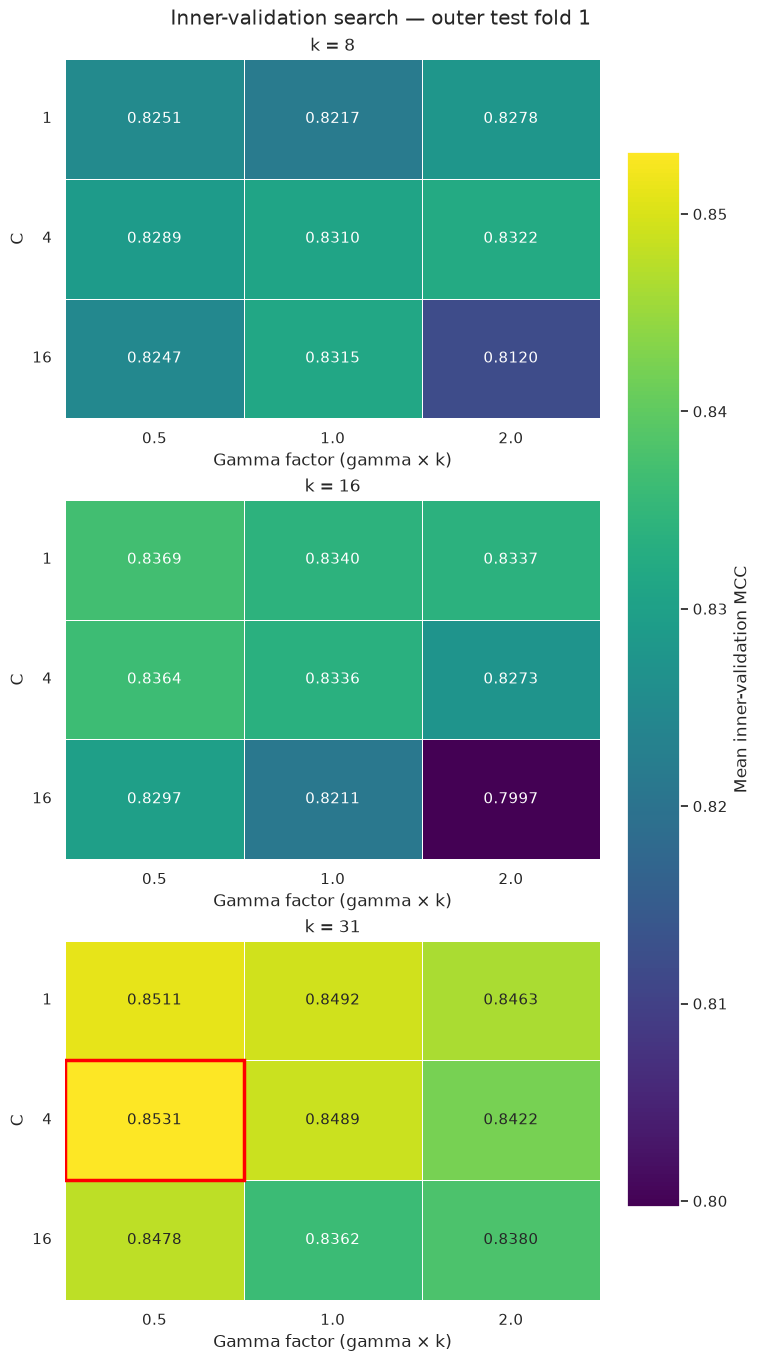

In [23]:
# Annotated heatmaps and PDF saving follow 03 section 2.3.
# Here the plotted values are the mean inner-validation MCC from section 4.3.
plot_scores = mean_inner_scores.copy()
plot_scores["gamma_factor"] = (plot_scores["gamma"] * plot_scores["k"]).round(6)
plot_k_values = sorted(plot_scores["k"].unique())

fig, axes = plt.subplots(
    len(plot_k_values), 1, figsize=(7.5, 4.5 * len(plot_k_values)),
    squeeze=False, layout="constrained"
)
for ax, k in zip(axes.flat, plot_k_values):
    score_matrix = (
        plot_scores[plot_scores["k"] == k]
        .pivot(index="C", columns="gamma_factor", values="mean_mcc")
        .sort_index()
        .sort_index(axis=1)
    )
    sns.heatmap(
        score_matrix, ax=ax, annot=True, fmt=".4f", cmap="viridis",
        vmin=plot_scores["mean_mcc"].min(), vmax=plot_scores["mean_mcc"].max(),
        linewidths=0.5, cbar=False, annot_kws={"fontsize": 11}
    )
    ax.set_title(f"k = {k}")
    ax.set_xlabel("Gamma factor (gamma × k)")
    ax.set_ylabel("C")
    ax.tick_params(axis="both", labelrotation=0)

    if k == best_params[0]:
        row = score_matrix.index.get_loc(best_params[1])
        column = score_matrix.columns.get_loc(round(best_params[2] * k, 6))
        ax.add_patch(plt.Rectangle(
            (column, row), 1, 1, fill=False, edgecolor="red", linewidth=2.5
        ))

fig.colorbar(
    axes[0, 0].collections[0], ax=axes.ravel().tolist(),
    label="Mean inner-validation MCC", shrink=0.85
)
fig.suptitle(f"Inner-validation search — outer test fold {test_fold}")
figure_path = figure_dir / f"4_3_inner_search_test_fold_{test_fold}.pdf"
fig.savefig(figure_path, format="pdf", bbox_inches="tight")
print("Plot saved in:", figure_path)
plt.show()


## 5. Outer refit and evaluation

We defined the five outer rounds using the saved partitions, with each test fold held out during its inner selection and outer-training refit (slides 37–41).

The fixed-grid evaluation was completed for all five outer folds.


### 5.1 Refit on the four outer-training folds

We defined `refit_outer_model(data, test_fold, best_params)` to train the selected procedure on all four outer-training folds. The function estimates n from their positive proteins, selects training and test rows from the cached table for that n, and fits a new RF ranking on outer training. It selects the chosen k columns and fits a fresh scaler and SVM with the selected C and gamma.

We kept the fitted objects, n, selected feature names/importances and aligned test features/labels in `outer_fit` for 5.2. The call below refits the current outer round using the settings chosen in 4.3; predictions and metrics will follow in 5.2. Its function definition can be loaded separately from this example call.

**Similar code:** the refit block on slide 40 of `04 - Methods - SVM.pdf` repeats feature extraction and ranking on the four outer-training folds. We reused the calls from our example in 3.5 and the scaler/SVC helpers from 3.3.


In [24]:
# Refit on four outer-training folds, following the refit block in SVM slide 40.
# Ranking follows section 3.5; scaling/SVC use section 3.3.
# Sequence features are read from the tables prepared in section 2.8.
def refit_outer_model(data, test_fold, best_params):
    outer_train = data[data["cv_fold"] != test_fold].copy()
    outer_test = data[data["cv_fold"] == test_fold].copy()
    k, C, gamma = best_params
    n = get_n(outer_train)

    X_train = get_cached_features(outer_train, n)
    X_test = get_cached_features(outer_test, n)
    y_train = X_train.index.map(
        outer_train.set_index("accession")["label"]
    ).values
    y_test = X_test.index.map(
        outer_test.set_index("accession")["label"]
    ).values

    _, ranked_features, ranked_importances = rank_features(X_train, y_train)
    selected_names = ranked_features[:k]
    scaler, model = fit_svm(X_train[selected_names], y_train, C, gamma)

    return {
        "test_fold": test_fold,
        "n": n,
        "k": k,
        "C": C,
        "gamma": gamma,
        "selected_names": selected_names,
        "selected_importances": ranked_importances[:k],
        "X_test": X_test[selected_names],
        "y_test": y_test,
        "scaler": scaler,
        "model": model,
    }



In [25]:
outer_fit = refit_outer_model(data, test_fold, best_params)
print("Outer test fold:", outer_fit["test_fold"])
print("Composition length:", outer_fit["n"])
print("Selected feature count:", outer_fit["k"])


Outer test fold: 1
Composition length: 22
Selected feature count: 31


### 5.2 Predict and record one external fold

We defined `evaluate_outer_model(outer_fit)` to predict the held-out fold with the scaler and SVM fitted in 5.1. It calculates precision, recall, accuracy, MCC and F1, and returns the round's settings/metrics, accession-level predictions and selected-feature ranks/importances.

The call below prepares `cv_per_round`, `cv_predictions` and `selected_features` for the current outer fold. These tables will contain one round until 5.3 adds the remaining folds. Test accessions and labels follow the row order of `outer_fit["X_test"]`, and importances retain the new outer-training RF ranking.

**Similar code:** prediction and metrics reuse our helpers from 3.3–3.4, based on sections 1 and 3 of `04_SVM-sklearn_revised.ipynb`. Slides 39–41 of `04 - Methods - SVM.pdf` specify external evaluation and reporting; the result records follow the table structure used in 03 section 5.


In [26]:
# Prediction and metrics reuse sections 3.3-3.4, as in the section 3.5 example.
# Here they evaluate the held-out outer fold, following SVM slides 39-41.
def evaluate_outer_model(outer_fit):
    y_pred = predict_svm(
        outer_fit["X_test"], outer_fit["scaler"], outer_fit["model"]
    )
    metrics = calculate_metrics(outer_fit["y_test"], y_pred)
    round_result = {
        "test_fold": outer_fit["test_fold"],
        "n": outer_fit["n"],
        "selected_k": outer_fit["k"],
        "C": outer_fit["C"],
        "gamma": outer_fit["gamma"],
        **metrics,
    }
    round_predictions = pd.DataFrame({
        "accession": outer_fit["X_test"].index,
        "test_fold": outer_fit["test_fold"],
        "label": outer_fit["y_test"],
        "prediction": y_pred,
    })
    round_features = pd.DataFrame({
        "test_fold": outer_fit["test_fold"],
        "feature": outer_fit["selected_names"],
        "rank": range(1, len(outer_fit["selected_names"]) + 1),
        "importance": outer_fit["selected_importances"],
    })
    return round_result, round_predictions, round_features


round_result, round_predictions, round_features = evaluate_outer_model(outer_fit)
cv_per_round = pd.DataFrame([round_result])
cv_predictions = round_predictions.copy()
selected_features = round_features.copy()

print("Completed outer rounds:", len(cv_per_round))
print("Test predictions:", len(cv_predictions))
cv_per_round


Completed outer rounds: 1
Test predictions: 1630


,test_fold,n,selected_k,C,gamma,precision,recall,accuracy,mcc,f1
0,1,22,31,4.0,0.016129,0.892216,0.841808,0.971779,0.850968,0.866279


### 5.3 Complete all five outer rounds

We combined the helpers from 4.1–5.2 to run all five outer rounds from scratch. Each execution resets the four result tables and includes fold 1 again; the single-round example in 5.2 remains separate from this complete evaluation. Each round reads n-specific feature rows from the tables in 2.8 for its own four inner splits, starts with the original ranges from 3.2, selects settings, refits on four folds and evaluates its held-out fold.

We defined `select_inner_model` to evaluate exactly the 27 combinations from 3.2 on the four inner splits: 108 SVM fits per outer round. It selects the highest mean validation MCC, keeping the first candidate in grid order for exact ties. The grid stays fixed even when a selected value is at a boundary. Selection finishes before outer refitting and prediction.

The loop adds metrics to `cv_per_round`, accession-level predictions to `cv_predictions`, selected-feature records to `selected_features` and all evaluated inner scores to `inner_scores`. It updates the tables after each completed round. When all five rounds finish, the prediction table should cover the 8,146 training proteins once each. Section 6 will summarize and export these results.

**Similar code:** slide 40 provides the nested workflow and slide 38 provides the original grid. We reused our preparation/scoring functions from 4.2–4.3 and refit/evaluation helpers from 5.1–5.2; per-round collection follows 03 section 5.

The outer bar counts completed rounds and shows the active fold and phase. Temporary bars show progress through the four RF fits and the 108 inner SVM fits, then disappear. Each completed fold leaves one line with its selected k, C, gamma factor and test MCC.


In [27]:
# Repeat the fixed 27-candidate inner search from section 4.3.
# Candidate averaging follows SVM slides 38-40.
def select_inner_model(inner_fits, test_fold):
    search_scores = score_inner_grid(inner_fits, parameter_grid, test_fold)
    mean_scores = (
        search_scores.groupby(["k", "C", "gamma"], sort=False, as_index=False)["mcc"]
        .mean()
        .rename(columns={"mcc": "mean_mcc"})
    )
    best_row = mean_scores.loc[mean_scores["mean_mcc"].idxmax()]
    best_params = (int(best_row["k"]), float(best_row["C"]), float(best_row["gamma"]))
    return best_params, search_scores


# Run all five outer rounds from scratch, following SVM slide 40.
# Per-round table collection follows section 5 of the 03 notebook.
cv_per_round = pd.DataFrame()
cv_predictions = pd.DataFrame()
selected_features = pd.DataFrame()
inner_scores = pd.DataFrame()

with tqdm(fold_ids, desc="Outer rounds", unit="fold", miniters=1, position=0) as outer_progress:
    for next_test_fold in outer_progress:
        outer_progress.set_postfix(test=next_test_fold, stage="features/RF")
        fold_inner_fits = prepare_inner_fits(data, next_test_fold)
        outer_progress.set_postfix(test=next_test_fold, stage="inner search")
        fold_best_params, fold_inner_scores = select_inner_model(
            fold_inner_fits, next_test_fold
        )
        outer_progress.set_postfix(test=next_test_fold, stage="outer refit")
        fold_outer_fit = refit_outer_model(data, next_test_fold, fold_best_params)
        outer_progress.set_postfix(test=next_test_fold, stage="test prediction")
        fold_result, fold_predictions, fold_features = evaluate_outer_model(fold_outer_fit)

        cv_per_round = pd.concat([cv_per_round, pd.DataFrame([fold_result])], ignore_index=True)
        cv_predictions = pd.concat([cv_predictions, fold_predictions], ignore_index=True)
        selected_features = pd.concat([selected_features, fold_features], ignore_index=True)
        inner_scores = pd.concat([inner_scores, fold_inner_scores], ignore_index=True)
        k, C, gamma = fold_best_params
        outer_progress.write(
            f"Fold {next_test_fold}: k={k}, C={C:g}, gamma factor={gamma * k:g}, "
            f"MCC={fold_result['mcc']:.3f}"
        )

cv_per_round = cv_per_round.sort_values("test_fold").reset_index(drop=True)
print("Completed outer rounds:", len(cv_per_round))
print("Test predictions:", len(cv_predictions))
cv_per_round


Outer rounds:  20%|██        | 1/5 [00:40<02:42, 40.59s/fold, stage=features/RF, test=2]    

Fold 1: k=31, C=4, gamma factor=0.5, MCC=0.851


Loading feature table: ../results/tables/04/feature_cache/training_features_n21.tsv


Outer rounds:  40%|████      | 2/5 [01:55<03:02, 60.80s/fold, stage=features/RF, test=3]    

Fold 2: k=31, C=4, gamma factor=0.5, MCC=0.848


...

Outer rounds:  80%|████████  | 4/5 [03:29<00:50, 50.37s/fold, stage=features/RF, test=5]    

Fold 4: k=31, C=1, gamma factor=1, MCC=0.828


Outer rounds: 100%|██████████| 5/5 [04:07<00:00, 49.58s/fold, stage=test prediction, test=5]

Fold 5: k=31, C=1, gamma factor=1, MCC=0.881
Completed outer rounds: 5
Test predictions: 8146


,test_fold,n,selected_k,C,gamma,precision,recall,accuracy,mcc,f1
0,1,22,31,4.0,0.016129,0.892216,0.841808,0.971779,0.850968,0.866279
1,2,22,31,4.0,0.016129,0.916667,0.812500,0.971762,0.847696,0.861446
2,3,22,31,4.0,0.016129,0.870968,0.920455,0.976673,0.882343,0.895028
3,4,22,31,1.0,0.032258,0.830601,0.863636,0.966237,0.828032,0.846797
4,5,22,31,1.0,0.032258,0.901734,0.886364,0.977287,0.881306,0.893983


## 6. Results and integration

We report each metric as mean ± standard error across the five outer test folds, following 03. The fixed 27-candidate evaluation was completed, and the result tables and figures were regenerated.


### 6.1 Per-round results and mean ± SE

We followed 03 sections 5.4–5.5 to summarize MCC, F1, precision, recall and accuracy across the five held-out folds. `cv_summary` reports the mean, sample standard deviation (`ddof = 1`) and standard error (`SD / sqrt(number of rounds)`) for each metric. The uncertainty in the printed results is SE. We displayed MCC first because the classes are imbalanced; accuracy is reported alongside the other metrics.

The cell saves `cv_per_round`, `cv_summary` and `cv_predictions` as three TSV files under `../results/tables/04/`. It keeps full precision in the files and rounds only the displayed tables and printed values.

**Similar code:** 03 sections 5.4–5.5 provide the per-round export and mean ± SE calculation. SVM slides 39–41 require the five-round summary; we added export of the accession-level predictions collected in 5.2–5.3.


In [28]:
# Per-round export and mean/SD/SE follow 03 sections 5.4-5.5.
# These are outer-test metrics, as required by SVM slides 39-41.
metric_columns = ["mcc", "f1", "precision", "recall", "accuracy"]
settings_columns = ["test_fold", "n", "selected_k", "C", "gamma"]
cv_per_round = cv_per_round[settings_columns + metric_columns]
metric_labels = {
    "precision": "Precision",
    "recall": "Recall",
    "accuracy": "Accuracy",
    "mcc": "MCC",
    "f1": "F1",
}
n_rounds = len(cv_per_round)
cv_summary = pd.DataFrame({
    "mean": cv_per_round[metric_columns].mean(),
    "std": cv_per_round[metric_columns].std(ddof=1),
})
cv_summary["stderr"] = cv_summary["std"] / np.sqrt(n_rounds)
cv_summary.index.name = "metric"

per_round_path = table_dir / "6_1_cv_per_round.tsv"
summary_path = table_dir / "6_1_cv_summary.tsv"
predictions_path = table_dir / "6_1_cv_predictions.tsv"
cv_per_round.to_csv(per_round_path, sep="\t", index=False)
cv_summary.to_csv(summary_path, sep="\t")
cv_predictions.to_csv(predictions_path, sep="\t", index=False)
print("Per-round table saved in:", per_round_path)
print("Summary table saved in:", summary_path)
print("Predictions saved in:", predictions_path)

print("Per-round results:")
display(cv_per_round.round(3))
print("Outer rounds:", n_rounds)
print("SVM metrics (mean ± standard error):")
for metric in metric_columns:
    mean_value = cv_summary.loc[metric, "mean"]
    error_value = cv_summary.loc[metric, "stderr"]
    print(f"{metric_labels[metric]}: {mean_value:.3f} ± {error_value:.3f}")

cv_summary.round(4)


Per-round table saved in: ../results/tables/04/6_1_cv_per_round.tsv
Summary table saved in: ../results/tables/04/6_1_cv_summary.tsv
Predictions saved in: ../results/tables/04/6_1_cv_predictions.tsv
Per-round results:


,test_fold,n,selected_k,C,gamma,mcc,f1,precision,recall,accuracy
0,1,22,31,4.0,0.016,0.851,0.866,0.892,0.842,0.972
1,2,22,31,4.0,0.016,0.848,0.861,0.917,0.812,0.972
2,3,22,31,4.0,0.016,0.882,0.895,0.871,0.920,0.977
3,4,22,31,1.0,0.032,0.828,0.847,0.831,0.864,0.966
4,5,22,31,1.0,0.032,0.881,0.894,0.902,0.886,0.977


Outer rounds: 5
SVM metrics (mean ± standard error):
MCC: 0.858 ± 0.010
F1: 0.873 ± 0.009
Precision: 0.882 ± 0.015
Recall: 0.865 ± 0.018
Accuracy: 0.973 ± 0.002


,mean,std,stderr
metric,,,
mcc,0.8581,0.0234,0.0105
f1,0.8727,0.0212,0.0095
precision,0.8824,0.0334,0.0149
recall,0.8650,0.0413,0.0185
accuracy,0.9727,0.0045,0.0020


### 6.2 Selected settings and feature records

We kept the selected n, k, C and gamma from each outer round, adding the gamma factor (`gamma × k`) for comparison. This factor is the numerator in `gamma = factor / k`, for example a factor of 0.5 means `gamma = 0.5/k`. The display below also shows the five highest-ranked selected features per round and their outer-training RF importances. The exported feature table retains all selected names, ranks and importances.

The cell saves `selected_features`, `inner_scores` and `feature_catalog` as three TSV files under `../results/tables/04/`. The inner-score table retains every evaluated combination and validation fold, using the fixed 27-candidate grid. The catalog records each feature's region and calculation, distinguishing first-n composition from the fixed-region descriptors. Values are rounded only for display.

**Similar code:** SVM slide 39 illustrates the settings table and slide 35 provides RF importances. We reused the records collected in 5.2–5.3 and the catalog from 2.7, following the TSV export convention in 03 section 5.


In [29]:
# Selected settings follow SVM slide 39; RF records come from sections 5.2-5.3.
# TSV export follows 03 section 5; the catalog was assembled in section 2.7.
selected_settings = cv_per_round[["test_fold", "n", "selected_k", "C", "gamma"]].copy()
selected_settings["gamma_factor"] = selected_settings["gamma"] * selected_settings["selected_k"]
feature_records = selected_features.sort_values(["test_fold", "rank"]).reset_index(drop=True)

selected_features_path = table_dir / "6_2_selected_features.tsv"
inner_scores_path = table_dir / "6_2_inner_scores.tsv"
catalog_path = table_dir / "6_2_feature_catalog.tsv"
feature_records.to_csv(selected_features_path, sep="\t", index=False)
inner_scores.to_csv(inner_scores_path, sep="\t", index=False)
feature_catalog.to_csv(catalog_path, sep="\t", index=False)
print("Selected features saved in:", selected_features_path)
print("Inner scores saved in:", inner_scores_path)
print("Feature catalog saved in:", catalog_path)

print("Selected settings:")
display(selected_settings.round(6))
print("Top 5 selected features per round:")
display(feature_records.groupby("test_fold", sort=False).head(5).round(4))


Selected features saved in: ../results/tables/04/6_2_selected_features.tsv
Inner scores saved in: ../results/tables/04/6_2_inner_scores.tsv
Feature catalog saved in: ../results/tables/04/6_2_feature_catalog.tsv
Selected settings:


,test_fold,n,selected_k,C,gamma,gamma_factor
0,1,22,31,4.0,0.016129,0.5
1,2,22,31,4.0,0.016129,0.5
2,3,22,31,4.0,0.016129,0.5
3,4,22,31,1.0,0.032258,1.0
4,5,22,31,1.0,0.032258,1.0


Top 5 selected features per round:


,test_fold,feature,rank,importance
0,1,tm_tendency_max_w19,1,0.2117
1,1,hydrophobic_stretch_length,2,0.1202
2,1,hydropathy_max_w5,3,0.1189
3,1,hydropathy_profile_mean_w5,4,0.0879
4,1,hydropathy_peak_position,5,0.0720
31,2,tm_tendency_max_w19,1,0.2135
32,2,hydrophobic_stretch_length,2,0.1314
33,2,hydropathy_max_w5,3,0.1082
34,2,hydropathy_profile_mean_w5,4,0.0900
35,2,aa_fraction_L,5,0.0757


### 6.3 Plot external-fold metrics

We followed 03 section 5.6 to plot the five metric means with horizontal error bars representing one standard error. Small grey points show the individual outer rounds; their vertical offsets separate overlapping values. The labels report mean ± SE.

The score axis spans 0.5–1.0, as in 03. Values come from `cv_per_round` and `cv_summary`, with rounding only in the labels. The figure is saved as `../results/figures/04/6_3_cv_metrics.pdf`.

**Similar code:** 03 section 5.6 provides this mean ± SE plot. We adapted its table names and title to the SVM results.


Plot saved in: ../results/figures/04/6_3_cv_metrics.pdf


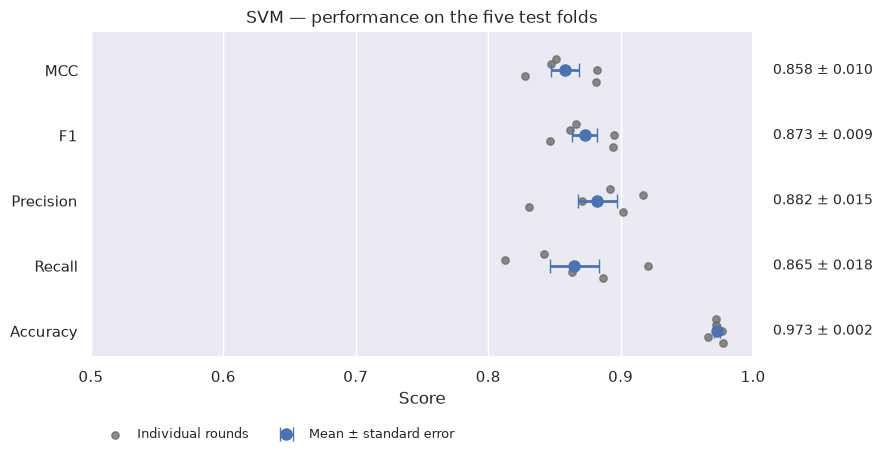

In [30]:
# Mean ± SE and individual-fold points follow 03 section 5.6.
y_positions = np.arange(len(metric_columns))
means = cv_summary.loc[metric_columns, "mean"].to_numpy()
errors = cv_summary.loc[metric_columns, "stderr"].to_numpy()

fig, ax = plt.subplots(figsize=(9, 4.8))
offsets = np.linspace(-0.18, 0.18, n_rounds)
for index, (_, row) in enumerate(cv_per_round.iterrows()):
    ax.scatter(
        row[metric_columns].to_numpy(dtype=float), y_positions + offsets[index],
        s=28, color="0.4", alpha=0.75, zorder=2,
        label="Individual rounds" if index == 0 else None
    )

ax.errorbar(
    means, y_positions, xerr=errors, fmt="o",
    color="C0", markersize=8, capsize=5, linewidth=2,
    label="Mean ± standard error", zorder=3
)
for position, mean_value, error_value in zip(y_positions, means, errors):
    ax.text(
        1.03, position, f"{mean_value:.3f} ± {error_value:.3f}",
        transform=ax.get_yaxis_transform(), va="center", fontsize=10
    )

ax.set_yticks(y_positions, [metric_labels[metric] for metric in metric_columns])
ax.set_ylim(len(metric_columns) - 0.6, -0.6)
ax.set_xlim(0.5, 1.0)
ax.set_xlabel("Score")
ax.set_title("SVM — performance on the five test folds")
ax.grid(axis="y", visible=False)
ax.legend(
    loc="upper left", bbox_to_anchor=(0, -0.18),
    ncol=2, frameon=False, fontsize=9
)
fig.tight_layout()

figure_path = figure_dir / "6_3_cv_metrics.pdf"
fig.savefig(figure_path, format="pdf", bbox_inches="tight")
print("Plot saved in:", figure_path)
plt.show()


### 6.4 Feature importance and ranking across folds

**Implemented and executed.** Bars show mean RF importance across the outer-training fits; grey points show the individual fit values. The heatmap reports ranks in the same feature order (1 = highest). All features were retained in all five rounds of this run, so each mean summarizes five recorded importances. These are RF training importances, not SVM attributions or test-set feature effects.

The cell reads this notebook's exported selected-feature table and saves `../results/figures/04/6_4_feature_ranking.pdf`.

**Similar code:** feature importances follow SVM slide 35; the heatmap and PDF conventions follow 03 section 2.3 and 04 section 4.3.


Plot saved in: ../results/figures/04/6_4_feature_ranking.pdf


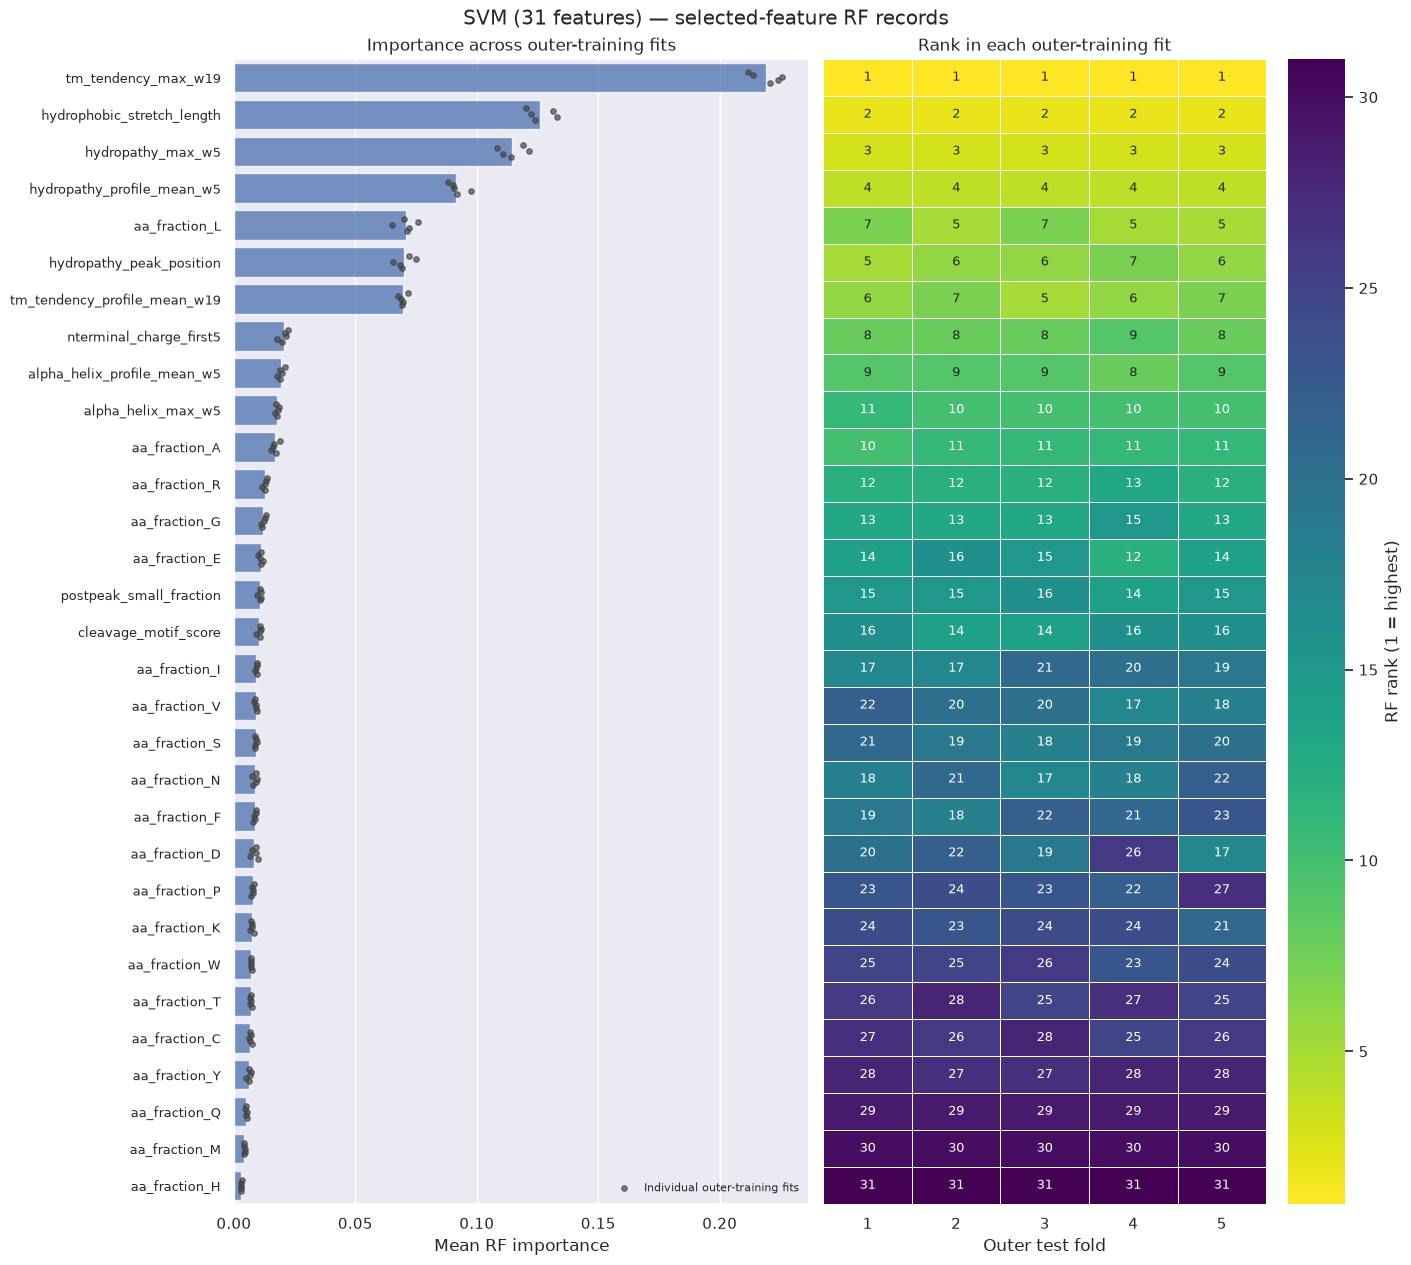

In [31]:
# RF importance follows SVM slide 35; plotting/export follows 04 and 03.
# Read this notebook's saved records; no model refitting is needed.
rf_records = pd.read_csv(table_dir / "6_2_selected_features.tsv", sep="\t")
importance_by_fold = rf_records.pivot(index="feature", columns="test_fold", values="importance")
rank_by_fold = rf_records.pivot(index="feature", columns="test_fold", values="rank")
mean_importance = importance_by_fold.mean(axis=1).sort_values(ascending=False)
feature_order = mean_importance.index
importance_by_fold = importance_by_fold.loc[feature_order]
rank_by_fold = rank_by_fold.loc[feature_order]

fig, axes = plt.subplots(
    1, 2, figsize=(14, 0.34 * len(feature_order) + 2),
    gridspec_kw={"width_ratios": [1.3, 1]}, layout="constrained"
)
y_positions = np.arange(len(feature_order))
axes[0].barh(y_positions, mean_importance, color="C0", alpha=0.75)
offsets = np.linspace(-0.16, 0.16, len(importance_by_fold.columns))
for index, fold in enumerate(importance_by_fold.columns):
    axes[0].scatter(
        importance_by_fold[fold], y_positions + offsets[index],
        color="0.25", s=15, alpha=0.65,
        label="Individual outer-training fits" if index == 0 else None
    )
axes[0].set_yticks(y_positions, feature_order, fontsize=9)
axes[0].set_ylim(len(feature_order) - 0.5, -0.5)
axes[0].set_xlabel("Mean RF importance")
axes[0].set_title("Importance across outer-training fits")
axes[0].grid(axis="y", visible=False)
axes[0].legend(loc="lower right", fontsize=8, frameon=False)

sns.heatmap(
    rank_by_fold, ax=axes[1], annot=True, fmt=".0f", annot_kws={"fontsize": 9},
    cmap="viridis_r", vmin=1, vmax=len(feature_order), yticklabels=False,
    linewidths=0.4, cbar_kws={"label": "RF rank (1 = highest)"}
)
axes[1].set_title("Rank in each outer-training fit")
axes[1].set_xlabel("Outer test fold")
axes[1].set_ylabel("")
axes[1].tick_params(axis="x", labelrotation=0)
fig.suptitle("SVM (31 features) — selected-feature RF records")

figure_path = figure_dir / "6_4_feature_ranking.pdf"
fig.savefig(figure_path, format="pdf", bbox_inches="tight")
print("Plot saved in:", figure_path)
plt.show()


**Observation.** Maximum TM tendency, hydrophobic extent, maximum hydropathy and mean hydropathy occupied ranks 1–4 in every outer-training fit. Their mean importances were 0.219, 0.126, 0.115 and 0.092, respectively. This agrees with the hydrophobic class differences in the supplementary feature exploration. The lower RF ranks do not establish that the other descriptors contain no useful information, and RF importance does not measure individual SVM contributions.


### 6.5 Pooled classification errors

**Implemented and executed.** The first panel contains the pooled counts from the five held-out folds. The second normalizes each actual-class row to 100%, making missed SP proteins and false-positive NO_SP proteins easier to compare. These row percentages are descriptive pooled rates, not the mean ± SE estimates in 6.1.

The cell reads the saved accession-level predictions and saves `../results/figures/04/6_5_confusion_matrix.pdf`.

**Similar code:** 03 section 5.7 supplies the count-based confusion matrix; we added the row-normalized panel.


Plot saved in: ../results/figures/04/6_5_confusion_matrix.pdf


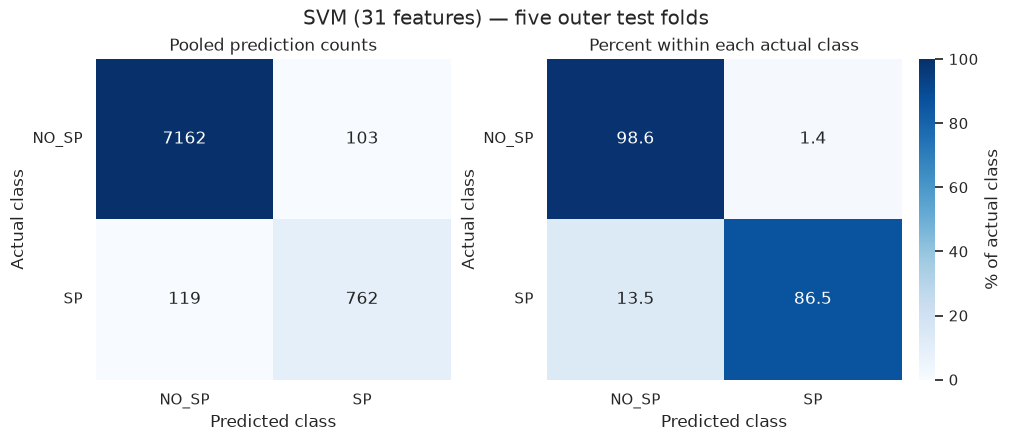

In [32]:
# Count-based confusion plots follow 03 section 5.7.
# Add row percentages so SP/NO_SP error rates can be compared despite class imbalance.
confusion_predictions = pd.read_csv(table_dir / "6_1_cv_predictions.tsv", sep="\t")
confusion_counts = pd.crosstab(
    confusion_predictions["label"], confusion_predictions["prediction"]
).reindex(index=[0, 1], columns=[0, 1], fill_value=0)
confusion_percent = confusion_counts.div(confusion_counts.sum(axis=1), axis=0) * 100

fig, axes = plt.subplots(1, 2, figsize=(10, 4.3), layout="constrained")
sns.heatmap(
    confusion_counts, ax=axes[0], annot=True, fmt="d", cmap="Blues", cbar=False,
    xticklabels=["NO_SP", "SP"], yticklabels=["NO_SP", "SP"]
)
sns.heatmap(
    confusion_percent, ax=axes[1], annot=True, fmt=".1f", cmap="Blues",
    vmin=0, vmax=100, cbar_kws={"label": "% of actual class"},
    xticklabels=["NO_SP", "SP"], yticklabels=["NO_SP", "SP"]
)
axes[0].set_title("Pooled prediction counts")
axes[1].set_title("Percent within each actual class")
for ax in axes:
    ax.set_xlabel("Predicted class")
    ax.set_ylabel("Actual class")
    ax.tick_params(axis="y", labelrotation=0)
fig.suptitle("SVM (31 features) — five outer test folds")

figure_path = figure_dir / "6_5_confusion_matrix.pdf"
fig.savefig(figure_path, format="pdf", bbox_inches="tight")
print("Plot saved in:", figure_path)
plt.show()


**Observation.** The pooled predictions contained 762 true positives, 119 false negatives, 103 false positives and 7,162 true negatives. The model missed 13.5% of annotated SP proteins and classified 1.4% of NO_SP proteins as SP. The percentage panel makes the missed-positive fraction visible despite the larger negative class. These pooled rates are distinct from the mean fold metrics in 6.1.


### 6.6 Observations and final integration

Across the five outer test folds, mean MCC was 0.858 ± 0.010 and F1 was 0.873 ± 0.009. Precision was 0.882 ± 0.015, recall 0.865 ± 0.018 and accuracy was 0.973 ± 0.002. The uncertainties are standard errors across rounds; MCC ranged from 0.828 to 0.882.

The pooled predictions contained 762 true positives, 119 false negatives, 103 false positives and 7,162 true negatives. All 8,146 training proteins were predicted once. The model recovered most annotated SP proteins while retaining high precision. Negatives dominate this dataset: predicting every protein negative would already give accuracy 0.892. MCC, precision, recall and F1 therefore give useful context for the accuracy. The reported means are averages of fold metrics, rather than metrics calculated from pooled counts.

All outer refits used n = 22 and selected k = 31, retaining the full feature set. Folds 1–3 selected C = 4 and gamma factor = 0.5; folds 4–5 selected C = 1 and gamma factor = 1. Gamma is the factor divided by k. Selection was restricted to the original 27 combinations in every round, including when a selected value lay at a boundary. These are the best settings within the evaluated grid. Selecting all features does not establish that each one was necessary.

Maximum TM tendency, hydrophobic extent, maximum hydropathy and mean hydropathy occupied the first four RF ranks in every outer-training fit. This agrees with the class differences in the supplementary feature exploration and supports their relevance for SP detection. Other descriptors showed weaker or overlapping distributions but could still contain useful information.

The completed Von Heijne analysis in 03 reported MCC 0.667 ± 0.018, F1 0.703 ± 0.016, precision 0.665 ± 0.030 and recall 0.751 ± 0.021. The SVM obtained higher mean scores on the same five held-out folds. This comparison describes the two implemented procedures: Von Heijne trained its matrix on three folds and chose a threshold on one validation fold, whereas the SVM used nested selection and refitted on four folds. The improvement cannot be attributed only to the classifier or the additional features.

We exported the metrics, predictions, selected-feature records, inner-search scores, feature catalog and figures. The results suggest that these N-terminal sequence descriptors support SP detection in this dataset. The independent benchmarking split remains reserved.

These nested-CV scores evaluate the complete feature extraction, selection and classification procedure. The settings selected in the five outer rounds are not a final production-model configuration. Selecting and fitting that final model is a separate stage.

**Similar code:** 03 section 5.10 provides the interpretation style. Values above come from the new fixed-grid 04 exports and the completed 03 tables.
